# EDA: generación eólica y consumo de Aruba

## Qué queremos aprender antes de entrenar

Predeciremos **dos cantidades a t+15 minutos**, con un modelo independiente para cada una. Las entradas solo podrán contener información disponible en el instante t.

- **Generación:** estimación de la potencia del parque Vader Piet, calculada a partir del viento; no es una medición de producción.
- **Consumo:** serie modelada a partir de energía mensual del CBS, perfiles horarios, meteorología y ruido; no es demanda medida.
- **Retardo (lag):** dato del pasado. `lag_1` corresponde a t−5 min y `lag_4` a t−20 min. Ninguno es el objetivo futuro.

Este notebook completa la inspección, calidad, distribuciones, relaciones y redundancia de `docs/EntrenamientoML.pdf` (págs. 10–50), respetando su prevención de fugas (págs. 53–55 y 78–83). **No entrena modelos ni modifica los CSV de entrada.** Las gráficas, tablas y conclusiones quedan en sus salidas.

**Cómo usarlo:** ejecutar todas las celdas en orden con el entorno del proyecto. Las comprobaciones se detienen si cambian las premisas del dataset; no eliminan problemas silenciosamente.

### Guía de lectura paso a paso

No hace falta entender todo el notebook de golpe. En cada apartado:

1. **Lee la pregunta y el motivo** antes de ejecutar el código.
2. **Ejecuta una celda pequeña** y observa su salida. Algunas solo preparan datos y no muestran nada.
3. **Lee cómo interpretar el resultado** antes de pasar al siguiente cálculo.
4. **Distingue observar de decidir:** las gráficas sugieren hipótesis; la validación posterior comprobará si ayudan a predecir.

### 0.0 Cargar las herramientas

La primera celda importa pandas para tablas, NumPy para cálculos y Matplotlib para gráficas. `display` permite mostrar tablas y `Markdown` redactar conclusiones calculadas. Importar una librería no entrena ningún modelo.

In [6]:
import hashlib
import json
import platform
import sys
from pathlib import Path

import holidays
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

### 0.1 Localizar el proyecto e importar nuestra función

**Qué hacemos:** buscamos la carpeta del proyecto y hacemos accesible `src/`.

**Por qué:** así el notebook funciona al abrir Jupyter desde la raíz o desde `notebooks/`. `add_exact_time_features` se utilizará más adelante para buscar valores en fechas exactas; todavía no estamos creando objetivos ni entrenando.

In [7]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'pyproject.toml').exists() and (p / 'src').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from energy_dispatch.features.build import add_exact_time_features

### 0.2 Definir frecuencia, horizonte y columnas

- `PASO = 5min`: separación esperada entre lecturas.
- `HORIZONTE = 15min`: cuánto queremos anticiparnos.
- `OBJETIVOS_ACTUALES`: las dos señales actuales, no sus respuestas futuras.
- `METEO`: variables meteorológicas y sus unidades.

**No confundas paso con horizonte:** avanzar una lectura son cinco minutos, mientras que predecir a t+15 supone mirar quince minutos hacia delante. Estas constantes documentan el problema; no se aprenden de los datos.

In [8]:
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.2})
PASO = pd.Timedelta('5min')
HORIZONTE = pd.Timedelta('15min')
ZONA = 'America/Aruba'
OBJETIVOS_ACTUALES = ['generacion_eolica_kw', 'consumo_estimado_isla_kw']
LAGS_EOLICA = [f'generacion_eolica_kw_lag_{i}' for i in range(1, 5)]
METEO = ['temperature_c', 'humidity_pct', 'wind_speed_kmh', 'wind_direction_deg',
         'pressure_hpa', 'precipitation_mm', 'visibility_km', 'uv_index']
METEO_MEDIA = [c for c in METEO if c != 'wind_direction_deg']
UNIDADES = ['°C', '%', 'km/h', 'grados', 'hPa', 'mm', 'km', 'índice']
NOMBRES = {'generacion_eolica_kw': 'Generación eólica estimada',
           'consumo_estimado_isla_kw': 'Consumo estimado'}
print({'Python': platform.python_version(), 'pandas': pd.__version__,
       'numpy': np.__version__, 'matplotlib': matplotlib.__version__})

{'Python': '3.14.8', 'pandas': '3.1.1', 'numpy': '2.5.4', 'matplotlib': '3.11.2'}


## 1. Inspección y reserva temporal

Primero comprobamos estructura y claves, sin usar estadísticas del futuro para seleccionar variables. Una lectura se identifica por **estación + timestamp**: compartir fecha entre estaciones es legítimo.

Reservamos los mismos cortes para todos los registros: primer **60 % de instantes para entrenamiento**, siguiente 20 % para validación y último 20 % para prueba. Son proporciones de instantes observados, no de días naturales. Validación y prueba quedan fuera de las distribuciones, correlaciones y conclusiones exploratorias. Más adelante también separaremos las **fechas de las respuestas t+15**.

El reparto 60/20/20 es una decisión inicial, no un óptimo demostrado; conserva un 80 % de desarrollo y un 20 % de prueba final.

In [9]:
CSV = ROOT / 'data/processed/5_island_consumption/aruba_readings_with_consumption.csv'
fdata = pd.read_csv(CSV)

### 1.1 Convertir fechas y comprobar las claves

**Qué hacemos:** copiamos el DataFrame, convertimos `timestamp` a una fecha con zona UTC y comprobamos que estén las columnas necesarias.

Una fila se identifica por `station_id` + `timestamp`. Dos estaciones pueden compartir una fecha sin que sea un duplicado.

**Cómo leer el resultado:** los `assert` no imprimen nada cuando se cumplen. Si uno falla, aparece un error explicando la premisa incumplida y debemos revisarla antes de continuar. No se están borrando filas.

In [10]:
datos = fdata.copy()
datos['timestamp'] = pd.to_datetime(datos['timestamp'], utc=True, errors='raise')
requeridas = {'station_id', 'timestamp', 'has_anomaly_flag', 'was_imputed',
              *METEO, *OBJETIVOS_ACTUALES, *LAGS_EOLICA}
assert requeridas.issubset(datos.columns), f'Faltan: {requeridas - set(datos.columns)}'
assert datos[['station_id', 'timestamp']].notna().all().all(), 'Hay claves ausentes'
assert not datos.duplicated(['station_id', 'timestamp']).any(), 'Hay claves duplicadas'
datos = datos.sort_values(['timestamp', 'station_id']).reset_index(drop=True)

### 1.2 Reservar el futuro antes de explorar

**Qué hacemos:** calculamos los cortes sobre fechas únicas y creamos `eda` solo con el primer 60 % de instantes.

**Por qué:** una misma fecha no debe quedar en entrenamiento para una estación y en prueba para otra. Tampoco queremos escoger variables después de mirar el futuro.

`inicio_validacion` e `inicio_prueba` son fechas de corte. Las etiquetas `E1`, `E2` y `E3` solo acortan los nombres de estaciones en las figuras.

In [11]:
fechas = pd.DatetimeIndex(datos['timestamp'].unique()).sort_values()
assert len(fechas) >= 10, 'No hay suficientes instantes para separar tres periodos'
inicio_validacion = fechas[int(len(fechas) * 0.60)]
inicio_prueba = fechas[int(len(fechas) * 0.80)]
eda = datos.loc[datos['timestamp'] < inicio_validacion].copy()
estaciones = sorted(datos['station_id'].unique())
etiquetas = {station: f'E{i}' for i, station in enumerate(estaciones, start=1)}

### 1.3 Leer el resumen inicial

La siguiente salida reúne tres cosas distintas:

1. **Procedencia:** ruta y huella SHA-256 para identificar el archivo analizado.
2. **Estructura:** filas, columnas, fechas y estaciones. Filas no significa instantes independientes.
3. **Tipos:** `info()` muestra cómo interpreta pandas cada columna y cuántos valores están informados.

`head(3)` permite reconocer el contenido sin imprimir el dataset completo. Estos recuentos estructurales no son una evaluación predictiva.

In [12]:
print(f'Archivo: {CSV.relative_to(ROOT)}')
print(f'SHA-256: {hashlib.sha256(CSV.read_bytes()).hexdigest()}')
print(f'Filas: {len(datos):,}; columnas: {datos.shape[1]}; instantes: {len(fechas):,}')
print(f'Periodo UTC: {fechas.min()} → {fechas.max()}')
print(f'Validación desde {inicio_validacion}; prueba desde {inicio_prueba}')
display(pd.Series(etiquetas, name='etiqueta').rename_axis('station_id').to_frame())
display(eda.head(3))
datos.info()

Archivo: data/processed/5_island_consumption/aruba_readings_with_consumption.csv
SHA-256: 515230077c14272103f4453cba85e893eebc37205a00134c5e33e273fd1e4e5f
Filas: 316,968; columnas: 35; instantes: 105,656
Periodo UTC: 2025-09-01 00:20:00+00:00 → 2026-09-17 21:55:00+00:00
Validación desde 2026-04-17 03:45:00+00:00; prueba desde 2026-07-06 13:00:00+00:00


,etiqueta
station_id,
82a31d3a-9895-42e5-8ea0-11e8cb15b964,E1
963fdb57-b257-472d-b56e-892b265c2524,E2
acb2fa5c-518a-4a38-b68d-bf8e3b041ccf,E3


,id,station_id,timestamp,temperature_c,humidity_pct,wind_speed_kmh,wind_direction_deg,pressure_hpa,precipitation_mm,visibility_km,...,suspicious_zero_visibility_km,has_anomaly_flag,was_imputed,wind_alert,generacion_eolica_kw,generacion_eolica_kw_lag_1,generacion_eolica_kw_lag_2,generacion_eolica_kw_lag_3,generacion_eolica_kw_lag_4,consumo_estimado_isla_kw
0,98a52139-9375-4ff1-94c6-78fa93645b67,82a31d3a-9895-42e5-8ea0-11e8cb15b964,2025-09-01 00:20:00+00:00,31.4,68.1,21.4,47.7,1013.1,0.0,11.7,...,False,False,False,CRITICAL,5040.144353,5020.563066,4973.894353,4905.373413,4822.9621,130149.33
1,7282b235-e71e-4b2f-9abe-b61db7521daf,963fdb57-b257-472d-b56e-892b265c2524,2025-09-01 00:20:00+00:00,31.9,68.4,22.7,41.6,1013.3,0.0,11.5,...,False,False,False,MODERATE,5040.144353,5020.563066,4973.894353,4905.373413,4822.9621,130149.33
2,3b4bd7f0-573c-4bb4-a9db-bc5c6bc6dca5,acb2fa5c-518a-4a38-b68d-bf8e3b041ccf,2025-09-01 00:20:00+00:00,31.2,68.4,27.4,44.4,1013.4,0.0,12.1,...,False,False,False,MODERATE,5040.144353,5020.563066,4973.894353,4905.373413,4822.9621,130149.33


<class 'pandas.DataFrame'>
RangeIndex: 316968 entries, 0 to 316967
Data columns (total 35 columns):
 #   Column                             Non-Null Count   Dtype              
---  ------                             --------------   -----              
 0   id                                 316968 non-null  str                
 1   station_id                         316968 non-null  str                
 2   timestamp                          316968 non-null  datetime64[us, UTC]
 3   temperature_c                      316968 non-null  float64            
 4   humidity_pct                       316968 non-null  float64            
 5   wind_speed_kmh                     316968 non-null  float64            
 6   wind_direction_deg                 316968 non-null  float64            
 7   pressure_hpa                       316968 non-null  float64            
 8   precipitation_mm                   316968 non-null  float64            
 9   visibility_km                      316968 non-nu

### 1.4 Entender para qué sirve cada columna

**Antes de escoger entradas**, distinguimos identificadores, meteorología, señales actuales, retardos y auditoría.

La tabla siguiente añade su función, su tipo y los valores ausentes o distintos que aparecen en entrenamiento. `nulos_train` y `distintos_train` describen este bloque, no todo el futuro reservado.

**Qué mirar:** una columna puede ser numérica y no tener sentido como predictor; una etiqueta de alerta tampoco es automáticamente el objetivo de nuestro problema de regresión.

In [13]:
roles = {}
for columna in datos.columns:
    if columna in OBJETIVOS_ACTUALES:
        roles[columna] = 'Señal actual estimada; el objetivo será su valor a t+15'
    elif columna in LAGS_EOLICA:
        roles[columna] = 'Retardo de generación (pasado)'
    elif columna in METEO:
        roles[columna] = 'Meteorología de una estación en t'
    elif columna in ['id', 'station_id', 'timestamp']:
        roles[columna] = 'Identificación / tiempo; no entrada numérica directa'
    elif columna == 'wind_alert':
        roles[columna] = 'Categoría derivada del viento actual, no objetivo de regresión'
    else:
        roles[columna] = 'Auditoría / calidad; no entrada inicial'
display(pd.DataFrame({
    'tipo': eda.dtypes.astype(str),
    'nulos_train': eda.isna().sum(),
    'distintos_train': eda.nunique(),
    'funcion': pd.Series(roles),
}))

,tipo,nulos_train,distintos_train,funcion
id,str,0,190179,Identificación / tiempo; no entrada numérica d...
station_id,str,0,3,Identificación / tiempo; no entrada numérica d...
timestamp,"datetime64[us, UTC]",0,63393,Identificación / tiempo; no entrada numérica d...
temperature_c,float64,0,141,Meteorología de una estación en t
humidity_pct,float64,0,365,Meteorología de una estación en t
wind_speed_kmh,float64,0,395,Meteorología de una estación en t
wind_direction_deg,float64,0,490,Meteorología de una estación en t
pressure_hpa,float64,0,192,Meteorología de una estación en t
precipitation_mm,float64,0,106,Meteorología de una estación en t
visibility_km,float64,0,98,Meteorología de una estación en t


## 2. Calidad: qué se limpió y qué sigue pendiente de revisar

No repetimos la limpieza a ciegas. El informe del paso 0 describe **todas las estaciones originales**, mientras que este notebook usa las tres seleccionadas y un periodo de entrenamiento: sus recuentos no son directamente comparables.

La limpieza permite interpolar un valor aislado con sus vecinos. Esa regla utiliza una lectura posterior y habría que sustituirla por una política causal para predecir en tiempo real si llegara a aplicarse. Se muestra `was_imputed` para comprobar si afecta al dataset actual.

Los nulos se cuentan; no se imputan automáticamente. La ausencia de nulos tampoco demuestra continuidad: una fila puede faltar por completo.

In [14]:
informe_path = ROOT / 'data/processed/0_cleaning/data_cleaning_report.json'
if informe_path.exists():
    informe_limpieza = json.loads(informe_path.read_text())
    display(pd.Series(informe_limpieza, name='paso_0_todas_las_estaciones').to_frame())
else:
    print('Informe del paso 0 no disponible; las comprobaciones actuales siguen ejecutándose.')

,paso_0_todas_las_estaciones
input_rows,1351008
rows_without_valid_key,0
exact_duplicates_removed,82944
invalid_measurements,0
isolated_values_imputed,0
rows_removed_with_unresolved_missing_values,0
network_gaps_detected,36
rows_with_anomaly_flag,69
output_rows,1268064


### 2.1 Distinguir el informe histórico del dataset que analizamos

**La tabla anterior** resume la limpieza original de todas las estaciones. Sus recuentos no son los del entrenamiento actual.

**Ahora** resumimos únicamente las estaciones y fechas de `eda`: cuántas filas hay, qué periodo cubren y cuántas fueron marcadas como anómalas o imputadas.

**Qué mirar:** una anomalía marcada no es una fila eliminada. Un valor imputado es una estimación que sustituyó a una ausencia, y debe distinguirse de una lectura original.

In [15]:
display(eda.groupby('station_id').agg(
    filas=('timestamp', 'size'),
    inicio=('timestamp', 'min'),
    fin=('timestamp', 'max'),
    filas_con_anomalia=('has_anomaly_flag', 'sum'),
    filas_imputadas=('was_imputed', 'sum'),
).rename(index=etiquetas))

,filas,inicio,fin,filas_con_anomalia,filas_imputadas
station_id,,,,,
E1,63393,2025-09-01 00:20:00+00:00,2026-04-17 03:40:00+00:00,2,0
E2,63393,2025-09-01 00:20:00+00:00,2026-04-17 03:40:00+00:00,2,0
E3,63393,2025-09-01 00:20:00+00:00,2026-04-17 03:40:00+00:00,2,0


### 2.2 Comprobar que los números se pueden utilizar

Comprobamos dos problemas diferentes:

- **Infinito:** no es una cantidad física utilizable.
- **Ausencia (`NaN`):** no conocemos el valor.

**Cómo leerlo:** si no aparece un error, las variables comprobadas no contienen ninguno de los dos casos en entrenamiento. Esto no demuestra que los valores sean físicamente correctos ni que no falten fechas completas: esas comprobaciones vienen después.

In [16]:
assert not np.isinf(eda[METEO + OBJETIVOS_ACTUALES + LAGS_EOLICA]).any().any()
assert eda[METEO + OBJETIVOS_ACTUALES + LAGS_EOLICA].notna().all().all(), (
    'Hay ausencias: revisar una política explícita antes de continuar con este EDA'
)

## 3. Una fila por instante para las dos predicciones

**Generación, consumo y retardos eólicos son señales insulares repetidas en las tres estaciones.** Primero verificamos la igualdad; solo entonces conservamos una copia. No sumamos esas repeticiones ni elegimos arbitrariamente el valor de una estación.

Para una primera tabla candidata se incorpora la **media simultánea de las tres estaciones** para cada variable meteorológica. No representa una nueva medición ni reproduce necesariamente las ponderaciones del generador: el viento del parque se estimó con distancias y el consumo original utilizó la meteorología de las 12 estaciones.

La dirección del viento es circular: 359° y 1° están cerca. Agregamos seno y coseno, no su media aritmética en grados. Conservamos los indicadores de calidad solo para auditoría.

In [17]:
senales = OBJETIVOS_ACTUALES + LAGS_EOLICA
por_instante = datos.groupby('timestamp', sort=True)
igualdad = por_instante[senales].nunique(dropna=False)
assert igualdad.eq(1).all().all(), 'Las señales insulares difieren entre estaciones'
assert por_instante['station_id'].nunique().eq(len(estaciones)).all(), (
    'Faltan estaciones en algunos instantes: no mezclar agregaciones de distinta cobertura'
)
display(igualdad.max().rename('max_valores_distintos_por_instante').to_frame())

,max_valores_distintos_por_instante
generacion_eolica_kw,1
consumo_estimado_isla_kw,1
generacion_eolica_kw_lag_1,1
generacion_eolica_kw_lag_2,1
generacion_eolica_kw_lag_3,1
generacion_eolica_kw_lag_4,1


### 3.1 Conservar una copia de las señales eléctricas

**Cómo leer la tabla anterior:** un máximo de `1` significa que, para cada fecha, las estaciones comparten el mismo valor de esa señal. Si difieren, la comprobación detiene el notebook.

**Ahora:** conservamos una copia de generación, consumo y retardos, y añadimos la media de cada variable meteorológica numérica no circular en ese mismo instante.

No estamos calculando la media histórica ni sumando tres parques eólicos: estamos pasando de tres filas de estación a una fila insular.

In [18]:
isla = por_instante[senales].first().join(por_instante[METEO_MEDIA].mean())

### 3.2 Tratar la dirección como un círculo

La media aritmética de 359° y 1° es 180°, pero ambos vientos apuntan casi al mismo sitio. Por eso convertimos cada ángulo en dos componentes, seno y coseno, y promediamos esas componentes.

**Resultado:** dos columnas describen la dirección agregada sin introducir un salto artificial entre 360° y 0°.

También conservamos si alguna estación tiene una marca de calidad, y creamos `isla_train` con solo el periodo de entrenamiento. No se está entrenando nada.

In [19]:
radianes = np.deg2rad(datos['wind_direction_deg'])
direccion = datos.assign(wind_direction_sin=np.sin(radianes),
                         wind_direction_cos=np.cos(radianes))
isla = isla.join(direccion.groupby('timestamp')[['wind_direction_sin', 'wind_direction_cos']].mean())
isla = isla.join(por_instante[['has_anomaly_flag', 'was_imputed']].max())
isla_train = isla.loc[isla.index < inicio_validacion].copy()
eolica = isla_train[['generacion_eolica_kw']]
consumo = isla_train[['consumo_estimado_isla_kw']]
print(f'Tabla insular: {len(isla):,} instantes; EDA: {len(isla_train):,} instantes de entrenamiento.')

Tabla insular: 105,656 instantes; EDA: 63,393 instantes de entrenamiento.


## 4. Estadísticas descriptivas (PDF, págs. 11–12)

Media y mediana describen el centro; desviación y rango intercuartílico (RIC) describen dispersión. Asimetría y curtosis ayudan a describir la forma, **no obligan a transformar los datos**.

Las señales eléctricas se resumen una sola vez por instante. La meteorología se resume tanto agregada como por estación. Los ceros pueden ser legítimos, especialmente en lluvia y UV; una columna constante en este entrenamiento es una candidata a revisar, no una razón para borrar datos originales.

In [20]:
numericas = isla_train[OBJETIVOS_ACTUALES + METEO_MEDIA]
resumen = numericas.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T

### 4.1 Completar y leer las estadísticas

`describe()` prepara el resumen básico. Ahora lo ampliamos y mostramos:

| Medida | Qué te cuenta |
|---|---|
| `mean` / `50%` | Media y mediana: dos maneras de describir el centro. |
| `std` / `varianza` | Cuánto varían los valores; la varianza tiene unidades al cuadrado. |
| `25%`, `75%` y `RIC` | Dónde está la mitad central de los datos y cuánto ocupa. |
| `1%` y `99%` | Referencias para los extremos sin depender solo del mínimo o máximo. |
| `asimetria` / `curtosis` | Descripción de la forma y las colas; no prueban normalidad. |
| `ceros_pct` / `nulos` | Ceros conocidos frente a valores desconocidos: no son lo mismo. |

**Qué mirar:** compara media con mediana y máximo con percentil 99. Una diferencia grande invita a investigar; no obliga a borrar datos ni aplicar logaritmos.

In [21]:
resumen['varianza'] = numericas.var()
resumen['RIC'] = numericas.quantile(0.75) - numericas.quantile(0.25)
resumen['asimetria'] = numericas.skew()
resumen['curtosis'] = numericas.kurt()
resumen['ceros_pct'] = numericas.eq(0).mean() * 100
resumen['nulos'] = numericas.isna().sum()
display(resumen.round(3))

,count,mean,std,min,1%,25%,50%,75%,99%,max,varianza,RIC,asimetria,curtosis,ceros_pct,nulos
generacion_eolica_kw,63393.0,5290.754,1475.529,2342.026,2785.517,4003.169,5249.443,6547.893,7954.661,13621.981,2.177186e+06,2544.723,0.309,0.039,0.000,0
consumo_estimado_isla_kw,63393.0,110285.439,15304.874,76568.190,81987.030,98296.990,110305.420,121141.950,145993.226,157715.910,2.342392e+08,22844.960,0.169,-0.605,0.000,0
temperature_c,63393.0,27.479,2.614,21.333,22.733,25.133,27.500,29.833,32.133,32.900,6.833000e+00,4.700,-0.042,-1.219,0.000,0
humidity_pct,63393.0,78.507,6.996,65.467,66.667,73.300,78.500,83.233,92.667,95.233,4.895000e+01,9.933,0.103,-0.824,0.000,0
wind_speed_kmh,63393.0,24.216,2.322,18.433,19.667,22.333,24.233,26.200,28.333,35.733,5.392000e+00,3.867,0.069,-0.370,0.000,0
pressure_hpa,63393.0,1014.345,1.253,1007.833,1012.197,1013.200,1014.167,1015.633,1016.200,1016.467,1.569000e+00,2.433,-0.342,0.479,0.000,0
precipitation_mm,63393.0,0.014,0.144,0.000,0.000,0.000,0.000,0.000,0.433,6.500,2.100000e-02,0.000,15.644,328.752,98.342,0
visibility_km,63393.0,11.989,0.208,8.033,11.500,11.867,12.000,12.100,12.400,12.733,4.300000e-02,0.233,-2.419,24.291,0.000,0
uv_index,63393.0,2.539,3.089,0.000,0.000,0.000,0.100,5.667,8.133,8.567,9.543000e+00,5.667,0.664,-1.253,47.343,0


### 4.2 Repetir el resumen por estación

**La tabla anterior** utiliza una fila por instante y meteorología agregada.

**Ahora** comprobamos las mediciones de cada estación por separado. Busca diferencias de nivel, dispersión y extremos que pudieran quedar ocultas en la media insular.

Una estación con mayor media de viento no es automáticamente más fiable: para afirmarlo necesitaríamos información adicional sobre sensores y ubicación.

In [22]:
display(eda.groupby('station_id')[METEO].agg(['min', 'median', 'mean', 'std', 'max'])
        .rename(index=etiquetas).round(3))

temperature_c                             humidity_pct         \
                     min median    mean    std   max          min median   
station_id                                                                 
E1                  20.8   27.9  27.731  2.733  34.0         64.9   78.4   
E2                  20.9   27.7  27.630  2.712  33.5         63.4   78.5   
E3                  20.0   27.2  27.074  2.712  33.0         64.1   78.3   

                                  ... visibility_km                        \
              mean    std    max  ...           min median    mean    std   
station_id                        ...                                       
E1          78.494  7.069  100.0  ...           0.5   12.0  11.989  0.363   
E2          78.630  7.219  100.0  ...           0.6   12.0  11.989  0.353   
E3          78.396  7.217  100.0  ...           0.5   12.0  11.988  0.367   

                 uv_index                            
             max      min median   mean    std  max  
station_id                                           
E1          13.2      0.0    0.0  2.541  3.095  8.9  
E2          13.3      0.0    0.0  2.539  3.094  9.0  
E3          13.3      0.0    0.0  2.538  3.093  9.0  

[3 rows x 40 columns]

### 4.3 Contar las categorías de alerta

`wind_alert` sí es categórica, por lo que tiene sentido contar sus etiquetas. **Nuestros objetivos de ML siguen siendo números**, no esas categorías.

**Cómo leerlo:** cada recuento corresponde a filas de estación del entrenamiento, no a eventos de alerta independientes. Muchas lecturas consecutivas pueden pertenecer al mismo episodio.

In [23]:
display(eda['wind_alert'].value_counts(dropna=False).rename('filas_train').to_frame())

,filas_train
wind_alert,
MODERATE,123588
CRITICAL,61359
NORMAL,5232


## 5. Continuidad temporal y cobertura

Se esperan lecturas cada cinco minutos. El calendario completo permite localizar instantes ausentes y mostrar huecos en las gráficas mediante `NaN`, **sin rellenarlos**.

Esta tabla analiza la disponibilidad del CSV final: el paso 4 eliminó filas sin retardos completos, por lo que un salto puede incluir tanto un corte original como los 20 minutos iniciales descartados tras él. No atribuimos toda la ausencia a fallos del sensor.

El calendario de cinco minutos que se crea a continuación se usa únicamente para visualizar y medir continuidad; no se incorpora como observaciones inventadas al entrenamiento.

In [24]:
calendario_train = pd.date_range(isla_train.index.min(), isla_train.index.max(), freq=PASO)
assert isla_train.index.isin(calendario_train).all(), 'Hay fechas fuera de la rejilla de 5 min'
rejilla = isla_train[OBJETIVOS_ACTUALES].reindex(calendario_train)

### 5.1 Localizar los huecos por sus fechas

Hemos construido el calendario esperado y una copia para dibujar. `reindex()` deja un `NaN` donde falta un instante; no calcula un sustituto.

**Ahora** restamos fechas consecutivas del CSV. Si el salto supera cinco minutos, contamos las lecturas ausentes y anotamos la primera y la última fecha que faltan.

Por ejemplo, entre las 10:00 y las 10:15 faltan las lecturas de las 10:05 y 10:10: un salto de quince minutos implica dos instantes ausentes.

In [25]:
linea = pd.DataFrame({'timestamp': isla_train.index})
linea['anterior'] = linea['timestamp'].shift(1)
linea['salto'] = linea['timestamp'] - linea['anterior']
huecos = linea.loc[linea['salto'] > PASO].copy()
huecos['instantes_ausentes'] = (huecos['salto'] / PASO - 1).astype(int)
huecos['primer_ausente'] = huecos['anterior'] + PASO
huecos['ultimo_ausente'] = huecos['timestamp'] - PASO
display(huecos[['primer_ausente', 'ultimo_ausente', 'salto', 'instantes_ausentes']])

,primer_ausente,ultimo_ausente,salto,instantes_ausentes
35996,2026-01-04 00:00:00+00:00,2026-01-11 00:15:00+00:00,7 days 00:25:00,2020
58720,2026-03-30 22:00:00+00:00,2026-03-31 22:15:00+00:00,1 days 00:25:00,292


### 5.2 Medir la cobertura

**La tabla anterior** localiza los cortes. Ahora resumimos cuánto calendario observado conservamos y comparamos la cobertura entre estaciones.

**Cómo leerlo:** una cobertura del 96 % no significa que los datos sean un 96 % correctos. Significa que existe una lectura para aproximadamente el 96 % de los instantes esperados dentro del intervalo analizado.

Estos huecos deben respetarse al dibujar y al construir retardos u objetivos.

In [26]:
print(f'Instantes ausentes en entrenamiento: {len(calendario_train) - len(isla_train):,}')
print(f'Cobertura del calendario: {len(isla_train) / len(calendario_train):.2%}')
display(eda.groupby('station_id')['timestamp'].nunique().rename(index=etiquetas)
        .rename('instantes_presentes').to_frame()
        .assign(instantes_esperados=len(calendario_train)))

Instantes ausentes en entrenamiento: 2,312
Cobertura del calendario: 96.48%


,instantes_presentes,instantes_esperados
station_id,,
E1,63393,65705
E2,63393,65705
E3,63393,65705


## 6. Evolución temporal: una semana y el periodo de entrenamiento

La semana permite apreciar variaciones de corto plazo. Las medias diarias permiten ver cambios de nivel sin dibujar cientos de miles de puntos. No son los datos con los que se entrenará.

Para evitar que unos pocos minutos representen un día entero, las medias diarias se muestran solo con **al menos el 80 % de las 288 lecturas esperadas**. Es una regla de visualización declarada, no de limpieza ni una elección ajustada buscando mejorar métricas. El tercer panel muestra la cobertura real y los días sin datos quedan en blanco en las señales.

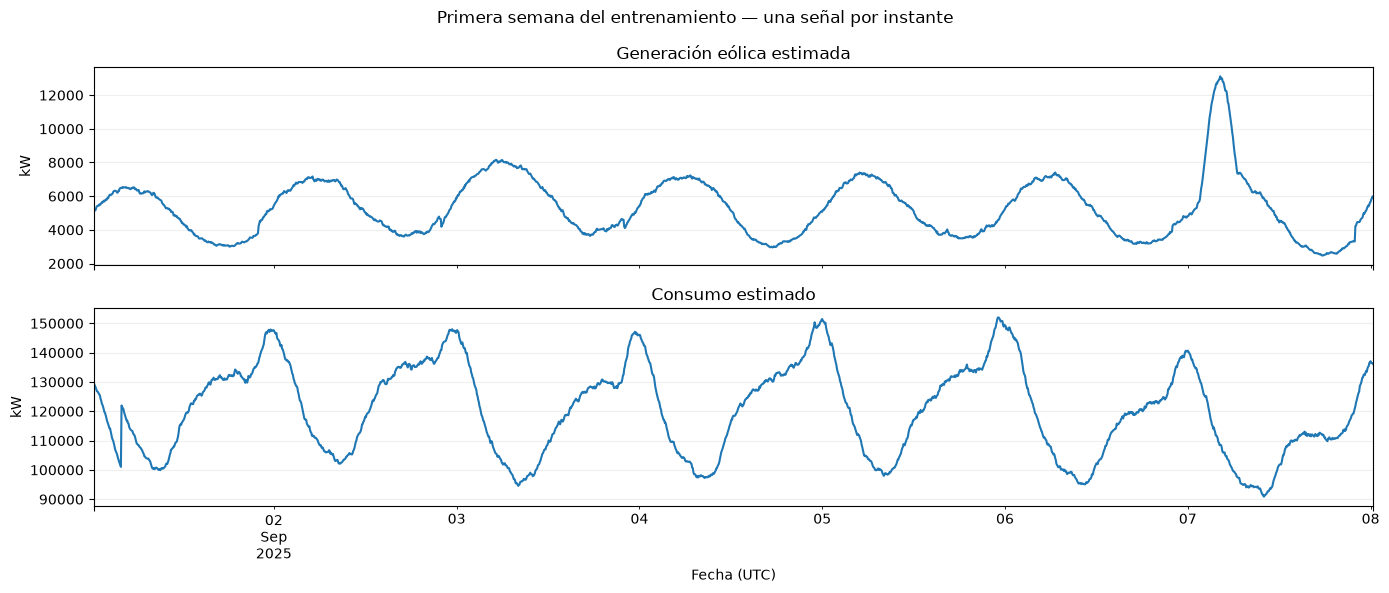

In [27]:
inicio = rejilla.index.min()
fin = inicio + pd.Timedelta(days=7)
fig, ejes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
for eje, columna in zip(ejes, OBJETIVOS_ACTUALES):
    rejilla.loc[inicio:fin, columna].plot(ax=eje, title=NOMBRES[columna])
    eje.set_ylabel('kW')
ejes[-1].set_xlabel('Fecha (UTC)')
fig.suptitle('Primera semana del entrenamiento — una señal por instante')
plt.tight_layout()
plt.show()

### 6.1 Interpretar la semana y preparar el resumen diario

**En la gráfica anterior:** el eje horizontal es tiempo y el vertical potencia en kW. Busca repeticiones diarias, cambios rápidos y tramos ausentes. Las dos señales tienen escalas distintas: compara sus patrones, no la altura entre paneles.

**Ahora cambiamos la pregunta:** en vez de observar cada cinco minutos, queremos ver si el nivel medio cambia entre días.

`resample('D')` agrupa por día UTC. Contamos las lecturas y calculamos la media; si un día no alcanza el 80 % de 288 lecturas, ocultamos su media en esta visualización. No cambia el dataset.

In [28]:
conteos_dia = rejilla.resample('D').count()
media_dia = rejilla.resample('D').mean().where(conteos_dia >= 0.80 * 288)

### 6.2 Dibujar las medias y su cobertura

Los dos primeros paneles mostrarán las medias diarias. El tercero indica cuántas lecturas respaldan cada día; la línea discontinua señala las 288 esperadas.

**Qué mirar:** cambios de nivel persistentes y días sin datos. No interpretes una caída del recuento como una caída de generación o consumo: son cantidades diferentes.

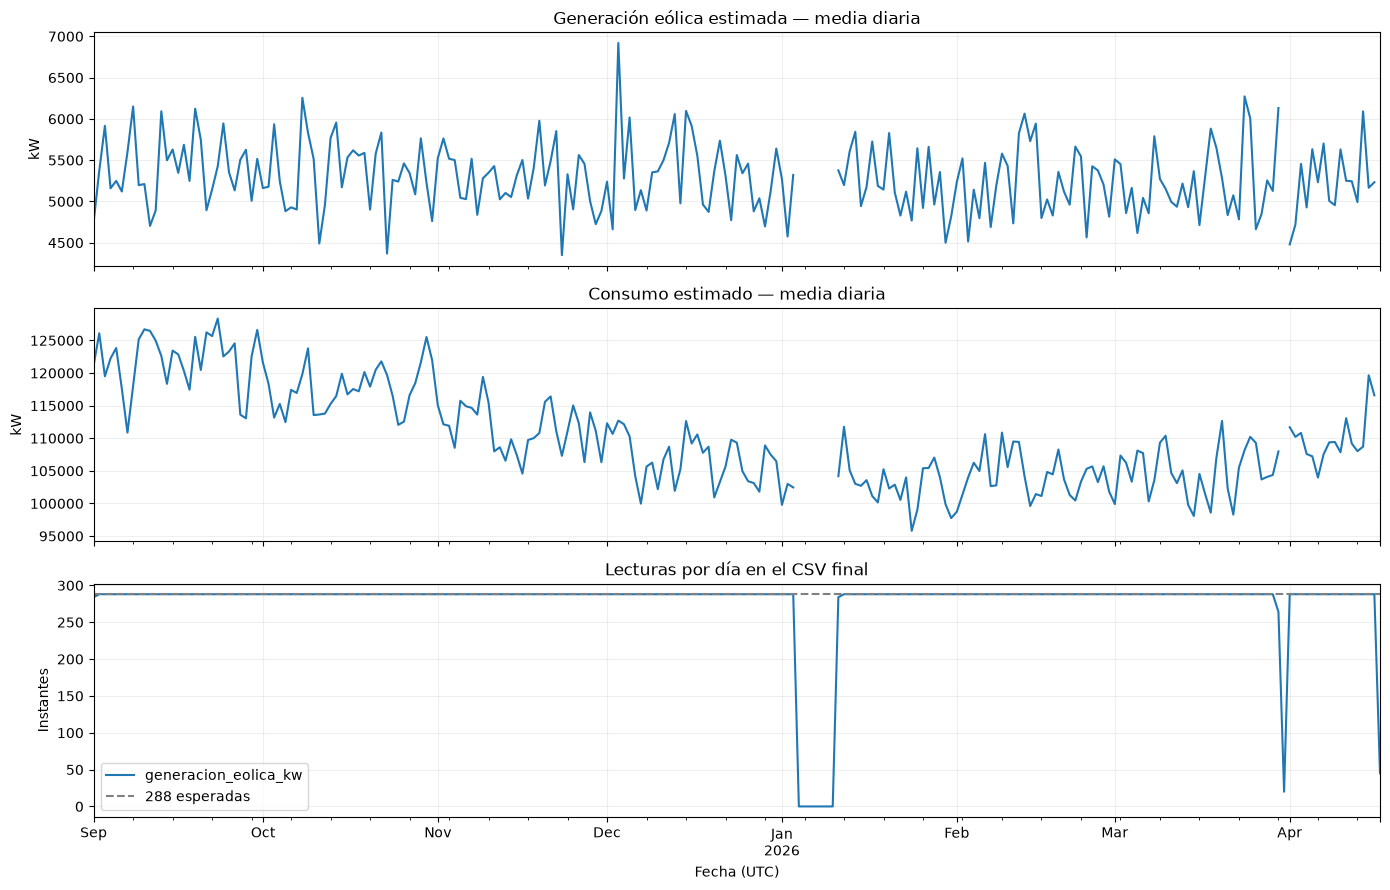

In [29]:
fig, ejes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for eje, columna in zip(ejes[:2], OBJETIVOS_ACTUALES):
    media_dia[columna].plot(ax=eje, title=NOMBRES[columna] + ' — media diaria')
    eje.set_ylabel('kW')
conteos_dia.iloc[:, 0].plot(ax=ejes[2], title='Lecturas por día en el CSV final')
ejes[2].axhline(288, color='gray', linestyle='--', label='288 esperadas')
ejes[2].set_ylabel('Instantes')
ejes[2].set_xlabel('Fecha (UTC)')
ejes[2].legend()
plt.tight_layout()
plt.show()

## 7. Distribuciones y extremos (PDF, págs. 12–20)

Cada señal eléctrica tiene su histograma y su diagrama de caja con unidades propias. Para meteorología se muestran histogramas por estación: evita ocultar diferencias espaciales en una distribución mezclada.

Un punto fuera de los bigotes de una caja es un **candidato a investigar**, no una fila que debamos eliminar. Un pico eólico o una caída importante puede ser precisamente el evento que interesa anticipar.

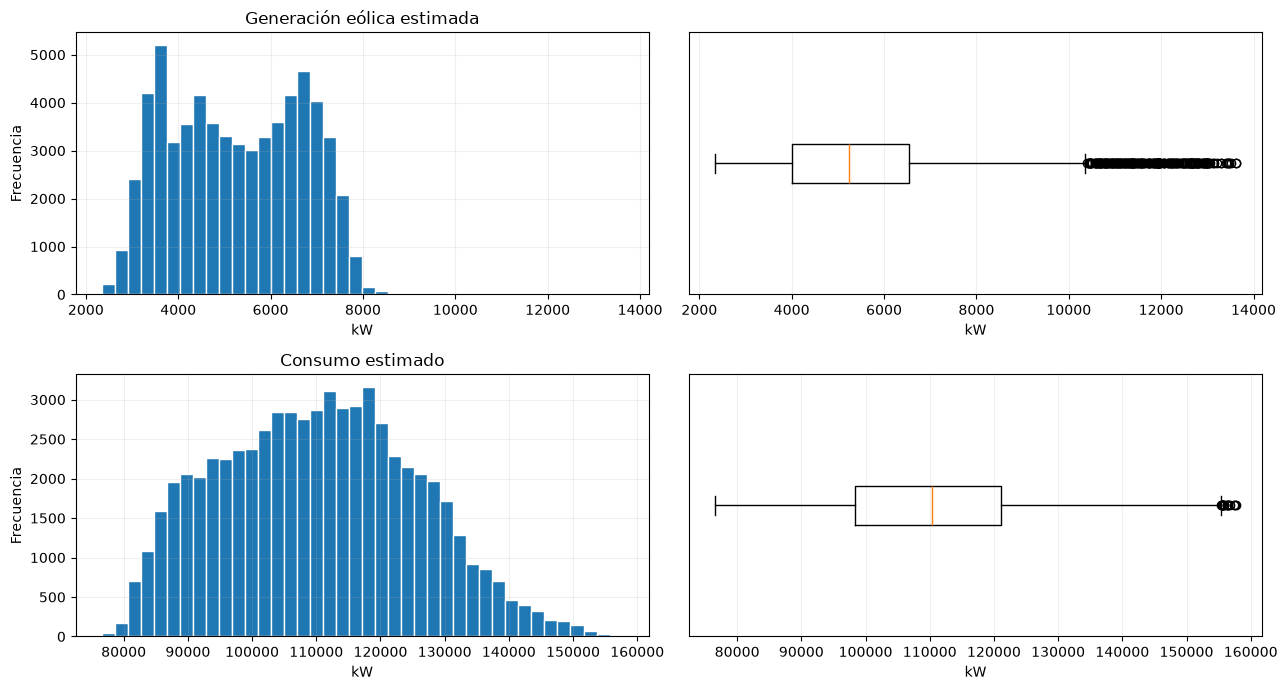

In [30]:
fig, ejes = plt.subplots(2, 2, figsize=(13, 7))
for fila, columna in enumerate(OBJETIVOS_ACTUALES):
    valores = isla_train[columna]
    ejes[fila, 0].hist(valores, bins=40, edgecolor='white')
    ejes[fila, 0].set_title(NOMBRES[columna])
    ejes[fila, 0].set_xlabel('kW')
    ejes[fila, 0].set_ylabel('Frecuencia')
    ejes[fila, 1].boxplot(valores.to_numpy(), orientation='horizontal')
    ejes[fila, 1].set_xlabel('kW')
    ejes[fila, 1].set_yticks([])
plt.tight_layout()
plt.show()

### 7.1 Leer las señales eléctricas y pasar a meteorología

**En los histogramas anteriores**, una barra alta indica un intervalo frecuente de potencia. El histograma no muestra cuándo ocurrió ese valor.

**En las cajas**, la línea central es la mediana y la caja contiene la mitad central de los datos. Los puntos exteriores son candidatos a investigar, no errores confirmados.

**Ahora** comparamos histogramas meteorológicos de `E1`, `E2` y `E3`. Cada panel conserva sus propias unidades. El eje vertical es densidad, no número de lecturas: permite comparar la forma de las distribuciones.

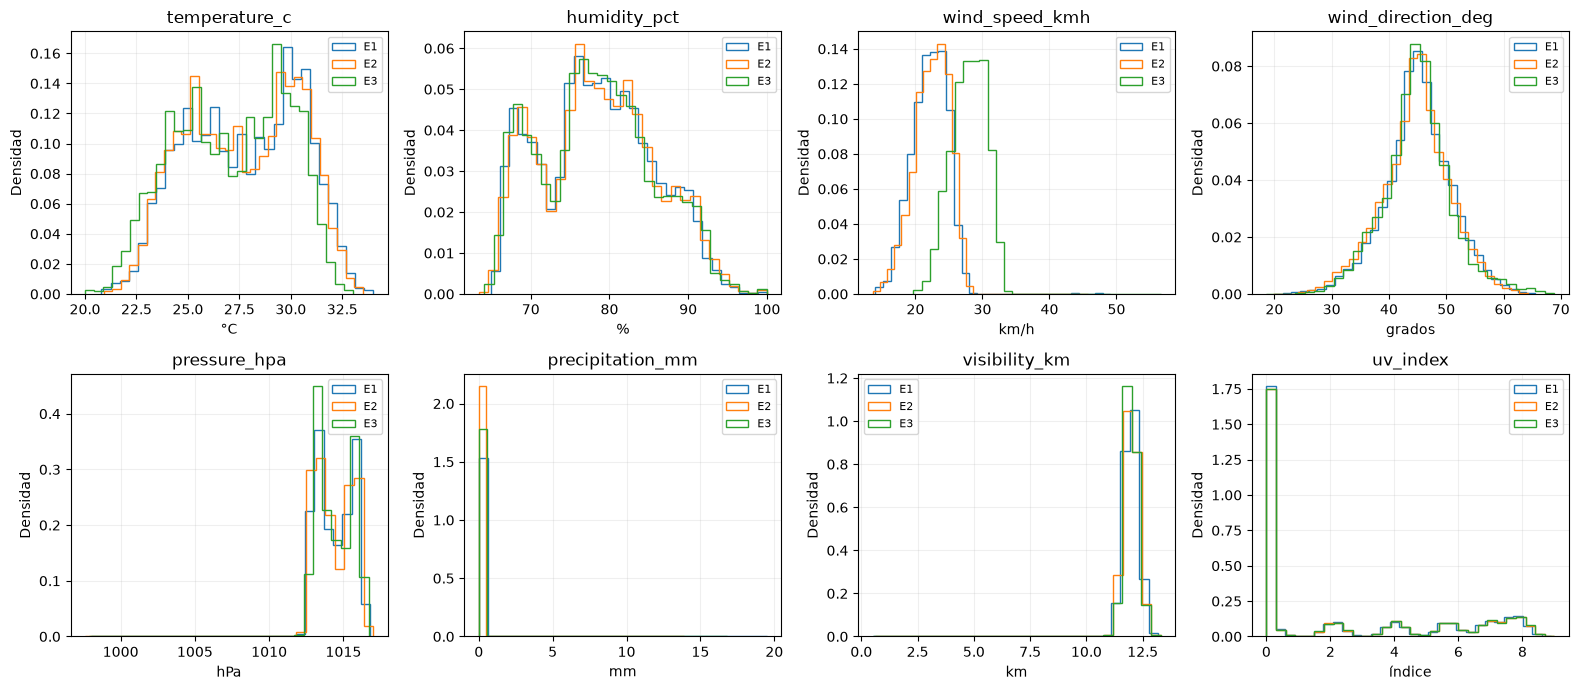

In [31]:
fig, ejes = plt.subplots(2, 4, figsize=(16, 7))
for eje, columna, unidad in zip(ejes.flat, METEO, UNIDADES):
    for station, grupo in eda.groupby('station_id'):
        eje.hist(grupo[columna], bins=30, density=True, histtype='step',
                 label=etiquetas[station])
    eje.set_title(columna)
    eje.set_xlabel(unidad)
    eje.set_ylabel('Densidad')
    eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 7.2 Coherencia física: comprobar lo posible antes de lo raro

Comprobamos rangos físicos conservadores y la capacidad nominal de 30.000 kW. No calibramos límites con validación o prueba. El consumo modelado debe ser positivo.

Calculamos candidatos IQR por estación, no mezclando climas locales. Excluimos la dirección en grados de esta regla lineal por su naturaleza circular. Si el RIC de lluvia o UV es cero, la regla puede señalar todos los valores positivos: **no significa que sean errores**. No se elimina ni winsoriza ningún extremo en este notebook.

In [32]:
rangos = {'temperature_c': (10, 45), 'humidity_pct': (0, 100),
          'wind_speed_kmh': (0, 180), 'wind_direction_deg': (0, 360),
          'pressure_hpa': (850, 1100), 'precipitation_mm': (0, 150),
          'visibility_km': (0, 100), 'uv_index': (0, 15)}
fuera_rango = {c: int((~eda[c].between(*limites) & eda[c].notna()).sum())
               for c, limites in rangos.items()}
fuera_rango['generacion_fuera_0_30000_kw'] = int(
    (~isla_train['generacion_eolica_kw'].between(0, 30000)).sum())
fuera_rango['consumo_no_positivo'] = int(isla_train['consumo_estimado_isla_kw'].le(0).sum())
display(pd.Series(fuera_rango, name='casos_a_revisar_train').to_frame())

,casos_a_revisar_train
temperature_c,0
humidity_pct,0
wind_speed_kmh,0
wind_direction_deg,0
pressure_hpa,0
precipitation_mm,0
visibility_km,0
uv_index,0
generacion_fuera_0_30000_kw,0
consumo_no_positivo,0


### 7.3 Buscar valores estadísticamente poco habituales

**La tabla anterior** comprueba límites físicos. Un cero significa que no encontramos infracciones de esa regla, no que el sensor sea perfecto.

**Ahora** aplicamos otra pregunta: ¿qué valores se alejan de la parte central de la distribución de su estación?

1. Calculamos los cuartiles Q1 y Q3.
2. Calculamos `RIC = Q3 − Q1`.
3. Señalamos valores fuera de `[Q1 − 1,5·RIC, Q3 + 1,5·RIC]`.

**Cómo leerlo:** la tabla cuenta candidatos, sin eliminarlos. Si el RIC de precipitación es cero, llover puede aparecer como atípico simplemente porque casi siempre no llueve.

In [33]:
candidatos = []
for station, grupo in eda.groupby('station_id'):
    for columna in METEO_MEDIA:
        q1, q3 = grupo[columna].quantile([0.25, 0.75])
        ric = q3 - q1
        mascara = ~grupo[columna].between(q1 - 1.5 * ric, q3 + 1.5 * ric)
        candidatos.append({'estacion': etiquetas[station], 'variable': columna,
                           'RIC': ric, 'candidatos': int(mascara.sum()),
                           'porcentaje': mascara.mean() * 100})
display(pd.DataFrame(candidatos).round(3))

,estacion,variable,RIC,candidatos,porcentaje
0,E1,temperature_c,4.6,0,0.000
1,E1,humidity_pct,10.3,43,0.068
2,E1,wind_speed_kmh,3.7,428,0.675
3,E1,pressure_hpa,2.4,238,0.375
4,E1,precipitation_mm,0.0,341,0.538
5,E1,visibility_km,0.4,1013,1.598
6,E1,uv_index,5.7,0,0.000
7,E2,temperature_c,4.7,0,0.000
8,E2,humidity_pct,10.5,60,0.095
9,E2,wind_speed_kmh,3.6,624,0.984


### 7.4 Revisar las anomalías ya marcadas

**No son lo mismo** un candidato IQR y una anomalía del pipeline: el primero depende de la distribución; la segunda puede señalar un salto brusco entre lecturas u otra regla de calidad.

Ahora mostramos las filas marcadas, el motivo y la meteorología de ese instante. Compara el episodio con la precipitación, visibilidad y lecturas vecinas antes de decidir.

**Decisión actual:** conservarlas y documentarlas. El notebook no borra extremos ni los sustituye.

In [34]:
anomalias = eda.loc[eda['has_anomaly_flag']].copy()
flags = [c for c in eda if c.startswith(('anomalous_jump_', 'suspicious_zero_'))]
if len(anomalias):
    anomalias['motivos'] = anomalias[flags].apply(
        lambda fila: ', '.join(fila.index[fila.astype(bool)]), axis=1)
    display(anomalias[['timestamp', 'station_id', 'motivos', *METEO]])
else:
    print('No hay anomalías marcadas en este entrenamiento.')
print(f'Filas de estación imputadas en entrenamiento: {int(eda.was_imputed.sum())}')

,timestamp,station_id,motivos,temperature_c,humidity_pct,wind_speed_kmh,wind_direction_deg,pressure_hpa,precipitation_mm,visibility_km,uv_index
2273,2025-09-03 15:25:00+00:00,acb2fa5c-518a-4a38-b68d-bf8e3b041ccf,anomalous_jump_visibility_km,21.7,83.3,27.4,48.6,1013.5,16.8,0.5,0.9
2276,2025-09-03 15:30:00+00:00,acb2fa5c-518a-4a38-b68d-bf8e3b041ccf,anomalous_jump_visibility_km,21.8,83.3,27.4,48.2,1013.5,0.0,11.8,5.5
50295,2025-10-29 05:25:00+00:00,82a31d3a-9895-42e5-8ea0-11e8cb15b964,anomalous_jump_visibility_km,30.3,78.2,24.9,47.4,1013.0,19.5,0.5,0.0
50298,2025-10-29 05:30:00+00:00,82a31d3a-9895-42e5-8ea0-11e8cb15b964,anomalous_jump_visibility_km,30.3,78.4,24.9,47.6,1013.0,0.0,11.4,0.0
103027,2025-12-29 06:10:00+00:00,963fdb57-b257-472d-b56e-892b265c2524,anomalous_jump_visibility_km,29.6,80.3,23.6,40.2,1014.1,13.9,0.6,0.0
103030,2025-12-29 06:15:00+00:00,963fdb57-b257-472d-b56e-892b265c2524,anomalous_jump_visibility_km,29.5,80.5,23.6,39.8,1014.1,0.0,11.9,0.0


Filas de estación imputadas en entrenamiento: 0


## 8. Comparación entre estaciones

Las estaciones comparten las señales eléctricas, pero no necesariamente las mismas condiciones meteorológicas. Comparamos sus distribuciones antes de adoptar la media como representación inicial. Una alternativa posterior sería conservar las variables de cada estación en columnas separadas y compararla mediante validación temporal.

Los boxplots no prueban diferencias estadísticamente significativas: las lecturas consecutivas tienen dependencia temporal y no aplicamos un ANOVA de observaciones independientes.

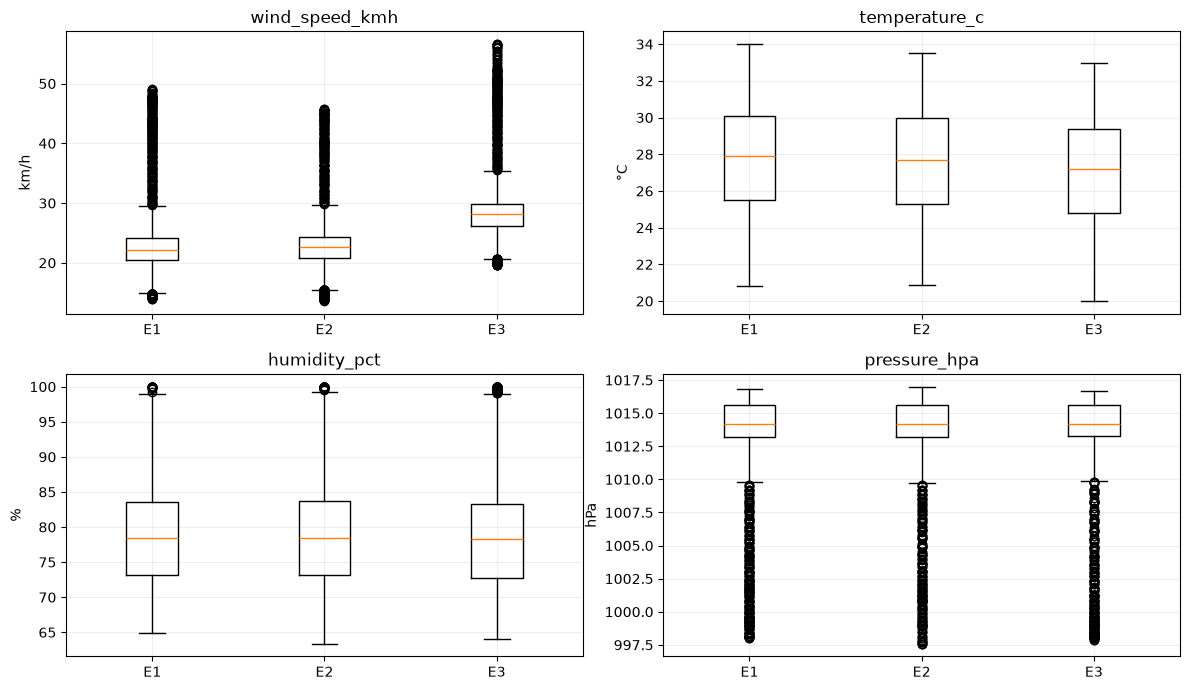

In [35]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 7))
for eje, columna, unidad in zip(ejes.flat,
        ['wind_speed_kmh', 'temperature_c', 'humidity_pct', 'pressure_hpa'],
        ['km/h', '°C', '%', 'hPa']):
    grupos = [eda.loc[eda.station_id == station, columna].to_numpy() for station in estaciones]
    eje.boxplot(grupos, tick_labels=[etiquetas[s] for s in estaciones])
    eje.set_title(columna)
    eje.set_ylabel(unidad)
plt.tight_layout()
plt.show()

## 9. Patrones de calendario en hora local de Aruba

Aruba utiliza UTC−4 sin cambio de hora. Comparamos días laborables con fines de semana/festivos oficiales. Las curvas son medias descriptivas, no pronósticos.

El consumo se construyó usando precisamente calendario y perfiles diarios: encontrar ese patrón comprueba coherencia de la simulación, **no valida la demanda real**. El mapa de recuentos muestra qué combinaciones tienen más o menos soporte. El entrenamiento no cubre varios ciclos anuales, por lo que no podemos demostrar una estacionalidad anual estable.

In [36]:
local_train = isla_train.index.tz_convert(ZONA)
festivos = holidays.country_holidays('AW', years=sorted(set(local_train.year)))
perfil = isla_train[OBJETIVOS_ACTUALES].assign(
    hora=local_train.hour, dia_semana=local_train.day_of_week,
    dia_libre=(local_train.day_of_week >= 5) | pd.Index(local_train.date).isin(festivos),
)
perfil['tipo_dia'] = np.where(perfil['dia_libre'], 'Fin de semana / festivo', 'Laborable')

### 9.1 Comparar las horas de días laborables y libres

La celda anterior añadió hora local, día de la semana y tipo de día. No calculó todavía una predicción.

**Ahora** agrupamos las observaciones por hora y tipo de día, y dibujamos su media.

**Cómo leerlo:** una diferencia entre curvas describe la simulación observada en entrenamiento. No asegura que el calendario sea suficiente para predecir ni demuestra un efecto causal. Los máximos y mínimos ayudan a proponer variables y segmentos de evaluación.

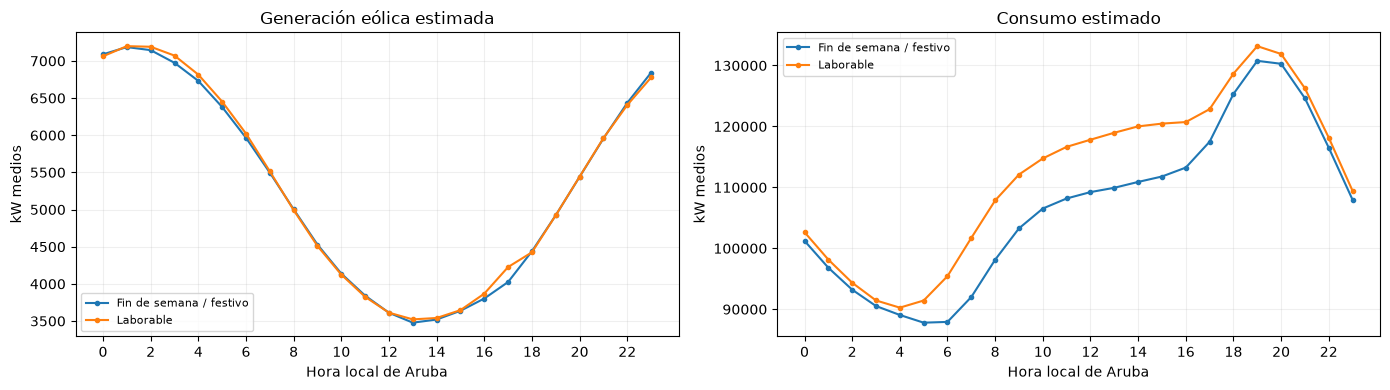

In [37]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
for eje, columna in zip(ejes, OBJETIVOS_ACTUALES):
    for tipo, grupo in perfil.groupby('tipo_dia'):
        grupo.groupby('hora')[columna].mean().reindex(range(24)).plot(
            ax=eje, marker='.', label=tipo)
    eje.set_title(NOMBRES[columna])
    eje.set_xlabel('Hora local de Aruba')
    eje.set_ylabel('kW medios')
    eje.set_xticks(range(0, 24, 2))
    eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 9.2 Añadir el día de la semana y comprobar el soporte

**En las curvas anteriores** cada punto mezcla los días de un mismo tipo. Ahora desglosamos cada combinación de hora y día de la semana.

Verás dos mapas:

- **Consumo medio:** el color representa kW medios.
- **Soporte:** el color representa cuántos instantes se utilizaron.

**Qué mirar:** interpreta ambos juntos. Una media con pocas observaciones tiene menos respaldo que otra con muchas; una ausencia no equivale a consumo cero.

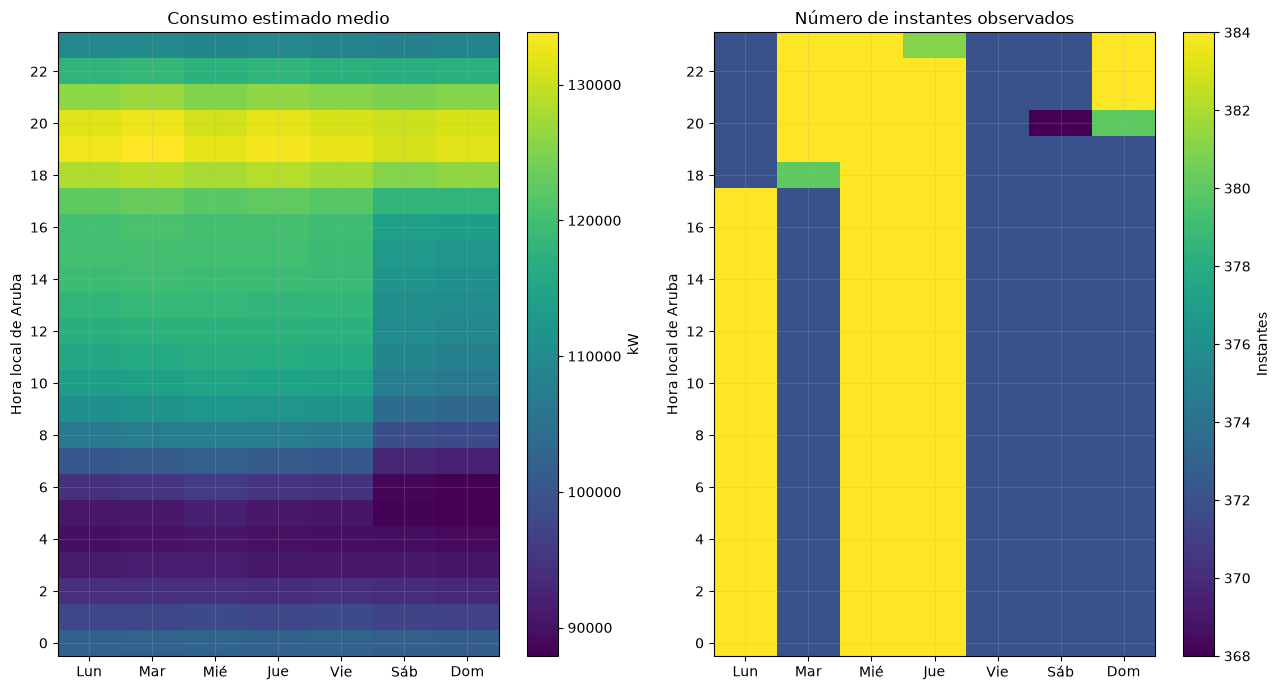

In [38]:
patron = perfil.pivot_table(index='hora', columns='dia_semana',
                           values='consumo_estimado_isla_kw', aggfunc='mean').reindex(
                               index=range(24), columns=range(7))
soporte = perfil.groupby(['hora', 'dia_semana']).size().unstack().reindex(
    index=range(24), columns=range(7))
fig, ejes = plt.subplots(1, 2, figsize=(13, 7))
for eje, tabla, titulo, unidad in zip(ejes, [patron, soporte],
        ['Consumo estimado medio', 'Número de instantes observados'], ['kW', 'Instantes']):
    imagen = eje.imshow(tabla.to_numpy(), aspect='auto', origin='lower')
    eje.set_title(titulo)
    eje.set_xticks(range(7), ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom'])
    eje.set_yticks(range(0, 24, 2))
    eje.set_ylabel('Hora local de Aruba')
    fig.colorbar(imagen, ax=eje, label=unidad)
plt.tight_layout()
plt.show()

### 9.3 Resumir los grupos con números

La tabla siguiente complementa las gráficas:

- `count`: cuántos instantes observados pertenecen a cada tipo de día.
- `mean`: nivel medio de la señal dentro del grupo.
- `std`: dispersión dentro del grupo.

No confundas una diferencia de medias con una prueba de significación. No estamos tratando las lecturas temporales como muestras independientes.

In [39]:
display(perfil.groupby('tipo_dia')[OBJETIVOS_ACTUALES].agg(['count', 'mean', 'std']).round(2))

generacion_eolica_kw                    \
                                       count     mean      std   
tipo_dia                                                         
Fin de semana / festivo                19912  5276.69  1453.40   
Laborable                              43481  5297.20  1485.53   

                        consumo_estimado_isla_kw                       
                                           count       mean       std  
tipo_dia                                                               
Fin de semana / festivo                    19912  106802.36  14951.20  
Laborable                                  43481  111880.51  15200.15

## 10. Relaciones meteorológicas actuales (PDF, págs. 15–16 y 26–31)

Los diagramas de densidad (`hexbin`) permiten ver muchos puntos sin taparlos unos con otros. Cada hexágono cuenta observaciones; el color usa una escala logarítmica de frecuencias.

Aquí relacionamos variables **del mismo instante** para entender el dataset. No demuestra capacidad de pronóstico a t+15. La generación es función del viento ponderado y el consumo es parcialmente función de temperatura, humedad y viento: las asociaciones pueden venir de esas fórmulas. La media meteorológica aquí usada solo resume las tres estaciones.

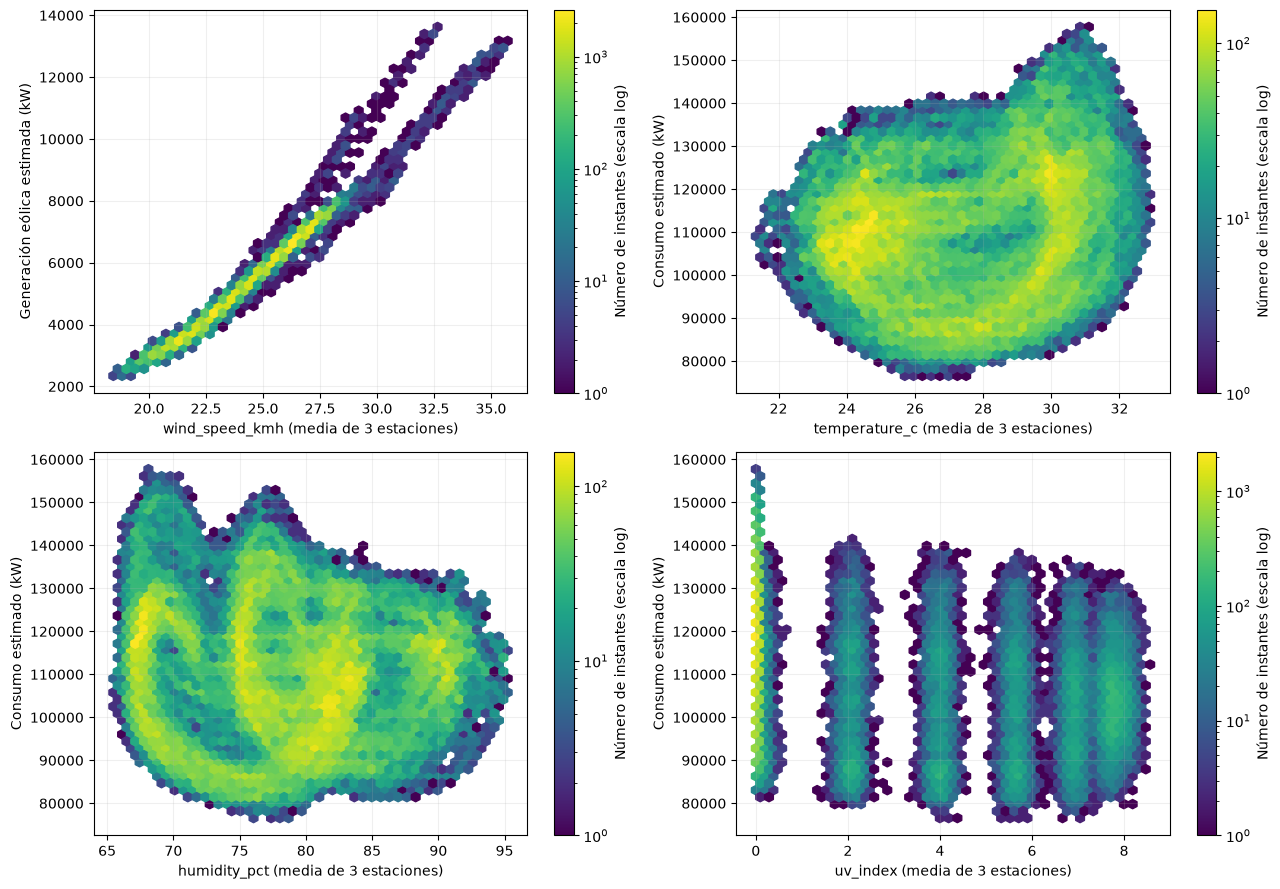

In [40]:
pares = [('wind_speed_kmh', 'generacion_eolica_kw'),
         ('temperature_c', 'consumo_estimado_isla_kw'),
         ('humidity_pct', 'consumo_estimado_isla_kw'),
         ('uv_index', 'consumo_estimado_isla_kw')]
fig, ejes = plt.subplots(2, 2, figsize=(13, 9))
for eje, (x, y) in zip(ejes.flat, pares):
    imagen = eje.hexbin(isla_train[x], isla_train[y], gridsize=45, mincnt=1, bins='log')
    eje.set_xlabel(x + ' (media de 3 estaciones)')
    eje.set_ylabel(NOMBRES[y] + ' (kW)')
    fig.colorbar(imagen, ax=eje, label='Número de instantes (escala log)')
plt.tight_layout()
plt.show()

## 11. Dependencia temporal: ¿cuánto se parece la serie a su pasado?

Calculamos correlación con retardos de 5–60 minutos, 24 horas y 7 días. La rejilla regular mantiene los huecos como `NaN`; no concatenamos segmentos separados al eliminar ausencias. Cada coeficiente usa solo pares con ambos valores disponibles.

Una asociación alta a 15 minutos sugiere que **persistencia** será una referencia exigente. No basta con obtener un R² alto: el futuro modelo deberá mejorar esa referencia en validación. No mostramos bandas de significación que supongan observaciones independientes ni exigimos estacionariedad para modelos de árboles.

In [41]:
correlaciones_temporales = []
for columna in OBJETIVOS_ACTUALES:
    serie = rejilla[columna]
    for pasos in [*range(1, 13), 288, 2016]:
        anterior = serie.shift(pasos)
        correlaciones_temporales.append({
            'senal': columna, 'minutos': pasos * 5,
            'correlacion': serie.corr(anterior),
            'pares_validos': int((serie.notna() & anterior.notna()).sum()),
        })
autocorrelaciones = pd.DataFrame(correlaciones_temporales)
display(autocorrelaciones.round(4))

,senal,minutos,correlacion,pares_validos
0,generacion_eolica_kw,5,0.9981,63390
1,generacion_eolica_kw,10,0.9957,63387
2,generacion_eolica_kw,15,0.9926,63384
3,generacion_eolica_kw,20,0.9890,63381
4,generacion_eolica_kw,25,0.9847,63378
5,generacion_eolica_kw,30,0.9799,63375
6,generacion_eolica_kw,35,0.9745,63372
7,generacion_eolica_kw,40,0.9687,63369
8,generacion_eolica_kw,45,0.9623,63366
9,generacion_eolica_kw,50,0.9554,63363


### 11.1 Interpretar los retardos cortos

**En la tabla anterior**, `minutos` indica cuánto retrocedemos, `correlacion` cuánto se asocian los valores y `pares_validos` cuántas parejas se pudieron comparar sin ausencias.

La gráfica siguiente muestra solo los retardos de 5 a 60 minutos. Los de 24 horas y 7 días permanecen en la tabla.

**Qué mirar:** si las barras siguen cerca de 1 a los quince minutos, el valor actual puede ser una referencia fuerte. Esto justifica comparar con persistencia, pero todavía no mide un modelo entrenado.

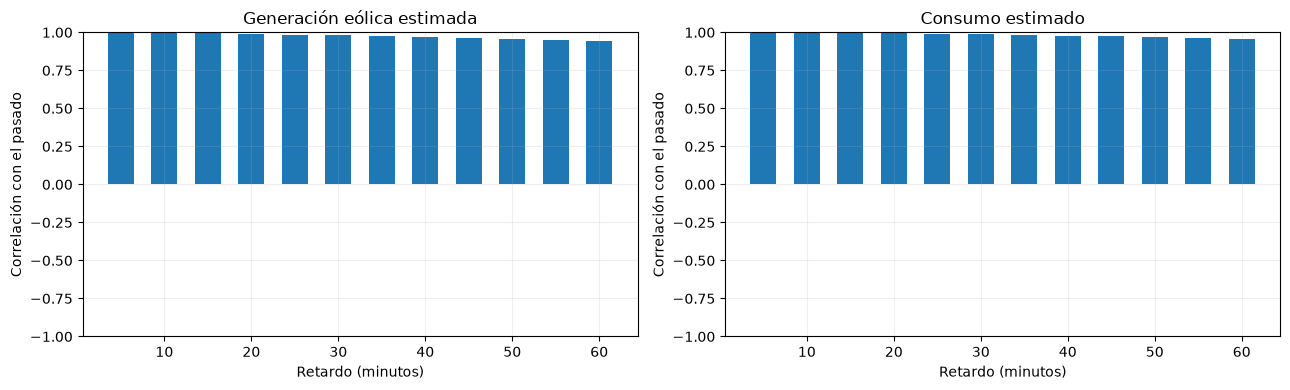

In [42]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for eje, columna in zip(ejes, OBJETIVOS_ACTUALES):
    corto = autocorrelaciones.query('senal == @columna and minutos <= 60')
    eje.bar(corto['minutos'], corto['correlacion'], width=3)
    eje.set_title(NOMBRES[columna])
    eje.set_xlabel('Retardo (minutos)')
    eje.set_ylabel('Correlación con el pasado')
    eje.set_ylim(-1, 1)
plt.tight_layout()
plt.show()

## 12. Objetivos futuros y retardos de consumo

Creamos `generacion_eolica_kw_t15` y `consumo_estimado_isla_kw_t15` buscando el dato de **exactamente t+15 minutos**. También añadimos cuatro retardos de consumo. Se hace sobre una fila por timestamp con una función reutilizable probada en `tests/test_exact_time_features.py`.

Un objetivo futuro es una **etiqueta para aprender y evaluar**, nunca una entrada. Si no existe la fecha solicitada, el valor queda ausente; no se interpola. Los retardos eólicos existentes se conservan, porque fueron calculados antes de eliminar las filas iniciales sin historia. Comprobamos su correspondencia con el pasado donde la fuente sigue presente en el CSV final.

Crear desplazamientos exactos o calendario no ajusta parámetros estadísticos. Aun así, al dividir hay que impedir que las etiquetas futuras del entrenamiento alcancen validación o prueba.

In [43]:
supervisado = isla.reset_index()
LAGS_CONSUMO = [f'consumo_estimado_isla_kw_lag_{i}' for i in range(1, 5)]
supervisado = add_exact_time_features(
    supervisado, 'consumo_estimado_isla_kw',
    {nombre: -i * PASO for i, nombre in enumerate(LAGS_CONSUMO, start=1)},
)

### 12.1 Diferenciar los retardos de las respuestas futuras

**La celda anterior** añadió información del pasado del consumo: 5, 10, 15 y 20 minutos antes.

**Ahora** creamos las dos respuestas que intentaremos predecir:

| Fila de las 10:00 | Fecha que debe consultar |
|---|---|
| Consumo `lag_1` | 09:55 |
| Consumo `lag_4` | 09:40 |
| Objetivo eólico `t15` | 10:15 |
| Objetivo de consumo `t15` | 10:15 |

`fecha_objetivo` registra esa fecha futura para comprobar las particiones. Si falta una respuesta, queda `NaN`: no inventamos una etiqueta.

In [44]:
TARGETS = [f'{columna}_t15' for columna in OBJETIVOS_ACTUALES]
for columna, target in zip(OBJETIVOS_ACTUALES, TARGETS):
    supervisado = add_exact_time_features(supervisado, columna, {target: HORIZONTE})
supervisado['fecha_objetivo'] = supervisado['timestamp'] + HORIZONTE

### 12.2 Representar el calendario como posibles entradas

El calendario se conoce de antemano, por lo que podemos obtenerlo sin observar el valor futuro de generación o consumo.

Usamos seno y coseno para que la hora dé una vuelta completa: las 23:55 y las 00:00 deben quedar cerca, no en extremos artificialmente alejados.

`dia_libre` distingue laborables de fines de semana/festivos. Estas variables son candidatas; su utilidad se comparará en validación, no se supone demostrada por haberlas creado.

In [45]:
local = supervisado['timestamp'].dt.tz_convert(ZONA)
calendario_festivos = holidays.country_holidays('AW', years=sorted(set(local.dt.year)))
hora_decimal = local.dt.hour + local.dt.minute / 60
supervisado['hora_sin'] = np.sin(2 * np.pi * hora_decimal / 24)
supervisado['hora_cos'] = np.cos(2 * np.pi * hora_decimal / 24)
supervisado['dia_libre'] = (local.dt.day_of_week >= 5) | local.dt.date.isin(calendario_festivos)

### 12.3 Comprobar los retardos eólicos que ya teníamos

No basta con confiar en el nombre `lag_1`: verificamos que su valor coincide con la generación de exactamente cinco minutos antes, y repetimos para los otros retardos.

**Cómo leer la tabla:**

- `pares_comprobados`: comparaciones cuyo dato original sigue disponible en este CSV.
- `fuente_ausente_en_csv_final`: casos que no podemos contrastar aquí porque el pipeline ya retiró algunas filas iniciales o posteriores a cortes.

No rellenamos esos casos ni los declaramos incorrectos por no poder comprobarlos en esta versión del archivo.

In [46]:
verificaciones_lag = []
for i, nombre in enumerate(LAGS_EOLICA, start=1):
    pasado = isla['generacion_eolica_kw'].reindex(isla.index - i * PASO).to_numpy()
    comparables = pd.notna(pasado) & isla[nombre].notna().to_numpy()
    assert np.allclose(isla[nombre].to_numpy()[comparables], pasado[comparables])
    verificaciones_lag.append({'lag': nombre, 'pares_comprobados': int(comparables.sum()),
                               'fuente_ausente_en_csv_final': int((~comparables).sum())})
display(pd.DataFrame(verificaciones_lag))

,lag,pares_comprobados,fuente_ausente_en_csv_final
0,generacion_eolica_kw_lag_1,105652,4
1,generacion_eolica_kw_lag_2,105648,8
2,generacion_eolica_kw_lag_3,105644,12
3,generacion_eolica_kw_lag_4,105640,16


### 12.4 Separar también las fechas de las respuestas

Una fila de las 10:00 tiene su respuesta a las 10:15. Si validación empieza a las 10:10, esa fila no pertenece al entrenamiento. Se excluye de ese ajuste aunque sus entradas sean anteriores al corte.

Aplicamos la misma regla entre validación y prueba. Los retardos de una predicción de validación pueden usar observaciones anteriores al corte: son historia legítimamente disponible en ese momento. No hay que prohibir todo solapamiento del pasado; lo que no puede invadir el futuro son las etiquetas o transformaciones aprendidas.

Las tablas de validación/prueba se reservan en memoria y aquí solo se muestran **fechas y recuentos**, no su rendimiento ni sus distribuciones.

In [47]:
conjuntos = {
    'train': supervisado.loc[(supervisado.timestamp < inicio_validacion)
                            & (supervisado.fecha_objetivo < inicio_validacion)].copy(),
    'validacion': supervisado.loc[(supervisado.timestamp >= inicio_validacion)
                                 & (supervisado.fecha_objetivo < inicio_prueba)].copy(),
    'prueba': supervisado.loc[supervisado.timestamp >= inicio_prueba].copy(),
}
train_futuro = conjuntos['train']

### 12.5 Comprobar que las respuestas no invaden el siguiente bloque

Hemos creado tres tablas, pero todavía debemos verificar sus límites.

Comprobamos que la última respuesta usada en entrenamiento sea anterior a la primera fecha de validación, y lo mismo entre validación y prueba. También comprobamos que ninguna tabla tenga timestamps repetidos.

**Si la celda no da error**, estas condiciones se cumplen. Esto evita una forma concreta de fuga temporal; no elimina las limitaciones de origen del consumo simulado.

In [48]:
assert train_futuro.fecha_objetivo.max() < conjuntos['validacion'].timestamp.min()
assert conjuntos['validacion'].fecha_objetivo.max() < conjuntos['prueba'].timestamp.min()
assert all(not tabla.timestamp.duplicated().any() for tabla in conjuntos.values())

### 12.6 Leer los tamaños y comprobar un ejemplo

La tabla siguiente muestra fechas, filas y respuestas ausentes por bloque. No contiene métricas ni distribuciones de validación o prueba.

**Qué mirar:** `sin_objetivo_*` puede ser mayor que cero cerca de un hueco o del final del archivo. Es preferible reconocer que falta la respuesta a inventarla.

Después mostramos unas filas de entrenamiento: compara `timestamp` con `fecha_objetivo` y verifica que estén separadas quince minutos. Las filas retiradas entre bloques son una medida de protección, no datos borrados del CSV.

In [49]:
resumen_particiones = []
for nombre, tabla in conjuntos.items():
    resumen_particiones.append({
        'conjunto': nombre, 'filas': len(tabla), 'desde': tabla.timestamp.min(),
        'hasta': tabla.timestamp.max(),
        'sin_objetivo_eolico': int(tabla[TARGETS[0]].isna().sum()),
        'sin_objetivo_consumo': int(tabla[TARGETS[1]].isna().sum()),
    })
display(pd.DataFrame(resumen_particiones).set_index('conjunto'))
print(f'Filas excluidas entre bloques por horizonte: {len(supervisado) - sum(map(len, conjuntos.values()))}')
display(train_futuro[['timestamp', 'fecha_objetivo', *OBJETIVOS_ACTUALES, *TARGETS]].head(6))

,filas,desde,hasta,sin_objetivo_eolico,sin_objetivo_consumo
conjunto,,,,,
train,63390,2025-09-01 00:20:00+00:00,2026-04-17 03:25:00+00:00,6,6
validacion,21128,2026-04-17 03:45:00+00:00,2026-07-06 12:40:00+00:00,3,3
prueba,21132,2026-07-06 13:00:00+00:00,2026-09-17 21:55:00+00:00,3,3


Filas excluidas entre bloques por horizonte: 6


,timestamp,fecha_objetivo,generacion_eolica_kw,consumo_estimado_isla_kw,generacion_eolica_kw_t15,consumo_estimado_isla_kw_t15
0,2025-09-01 00:20:00+00:00,2025-09-01 00:35:00+00:00,5040.144353,130149.33,5169.224378,128198.01
1,2025-09-01 00:25:00+00:00,2025-09-01 00:40:00+00:00,5113.900492,129154.51,5303.434365,127694.19
2,2025-09-01 00:30:00+00:00,2025-09-01 00:45:00+00:00,5158.859217,128773.16,5392.685627,126861.01
3,2025-09-01 00:35:00+00:00,2025-09-01 00:50:00+00:00,5169.224378,128198.01,5423.193028,126738.55
4,2025-09-01 00:40:00+00:00,2025-09-01 00:55:00+00:00,5303.434365,127694.19,5431.848201,126519.24
5,2025-09-01 00:45:00+00:00,2025-09-01 01:00:00+00:00,5392.685627,126861.01,5431.287249,126056.34


### 12.7 Comprobar de forma independiente cada respuesta

Volvemos a buscar el valor de la señal original en `fecha_objetivo` y lo comparamos con la columna `*_t15`.

Es una comprobación distinta de mirar unas primeras filas: recorre todas las etiquetas del entrenamiento. Las ausencias deben coincidir también.

**Resultado esperado:** ningún error. Si una respuesta estuviera desplazada a la fecha equivocada, esta celda detendría el análisis antes de entrenar.

In [50]:
# Verificación independiente de las etiquetas por timestamp, solo en entrenamiento.
for actual, target in zip(OBJETIVOS_ACTUALES, TARGETS):
    esperado = isla[actual].reindex(pd.DatetimeIndex(train_futuro.fecha_objetivo)).to_numpy()
    np.testing.assert_allclose(train_futuro[target].to_numpy(), esperado, equal_nan=True)

## 13. Relaciones con los objetivos a t+15 (PDF, págs. 26–31)

Definimos entradas **candidatas**, no una selección final automática. La generación y el consumo actuales son legítimos para anticipar el futuro si están disponibles en t. En un sistema real no disponemos de consumo medido en este proyecto: usar la estimación actual debe declararse como supuesto de simulación.

Pearson mide asociación lineal y Spearman asociación monótona. Ninguno descubre todas las relaciones no lineales. No descartamos variables por un umbral de correlación. La dirección entra mediante seno/coseno y no como grados lineales; tampoco correlacionamos identificadores como números.

Cada matriz incluye un solo objetivo futuro para **analizarlo**; esa última columna no forma parte de las entradas del modelo. Todos los cálculos de esta sección utilizan exclusivamente entrenamiento.

In [51]:
CALENDARIO_FEATURES = ['hora_sin', 'hora_cos', 'dia_libre']
features_eolica = ['generacion_eolica_kw', *LAGS_EOLICA, *METEO_MEDIA,
                   'wind_direction_sin', 'wind_direction_cos', *CALENDARIO_FEATURES]
features_consumo = ['consumo_estimado_isla_kw', *LAGS_CONSUMO,
                    'temperature_c', 'humidity_pct', 'wind_speed_kmh', *CALENDARIO_FEATURES]
problemas = {
    'Eólica': {'features': features_eolica, 'target': TARGETS[0]},
    'Consumo': {'features': features_consumo, 'target': TARGETS[1]},
}

### 13.1 Calcular Pearson y Spearman por problema

**La celda anterior** solo definió qué columnas podríamos entregar a cada modelo (`features`) y cuál sería su respuesta (`target`). No hizo una selección estadística ni un entrenamiento.

Ahora calculamos las correlaciones solo con ejemplos completos de entrenamiento. `dropna()` crea una muestra para este cálculo; no rellena valores ni modifica el dataset original.

**Cómo leer las matrices:** rojo indica asociación positiva y azul negativa; cerca de cero significa asociación débil según esa medida, no inutilidad demostrada. La diagonal vale 1 porque cada variable se compara consigo misma.

La tabla ordenada permite leer los coeficientes con el objetivo futuro. **Un 0,99 no significa 99 % de aciertos.** Una relación alta entre retardos tampoco obliga a descartarlos.

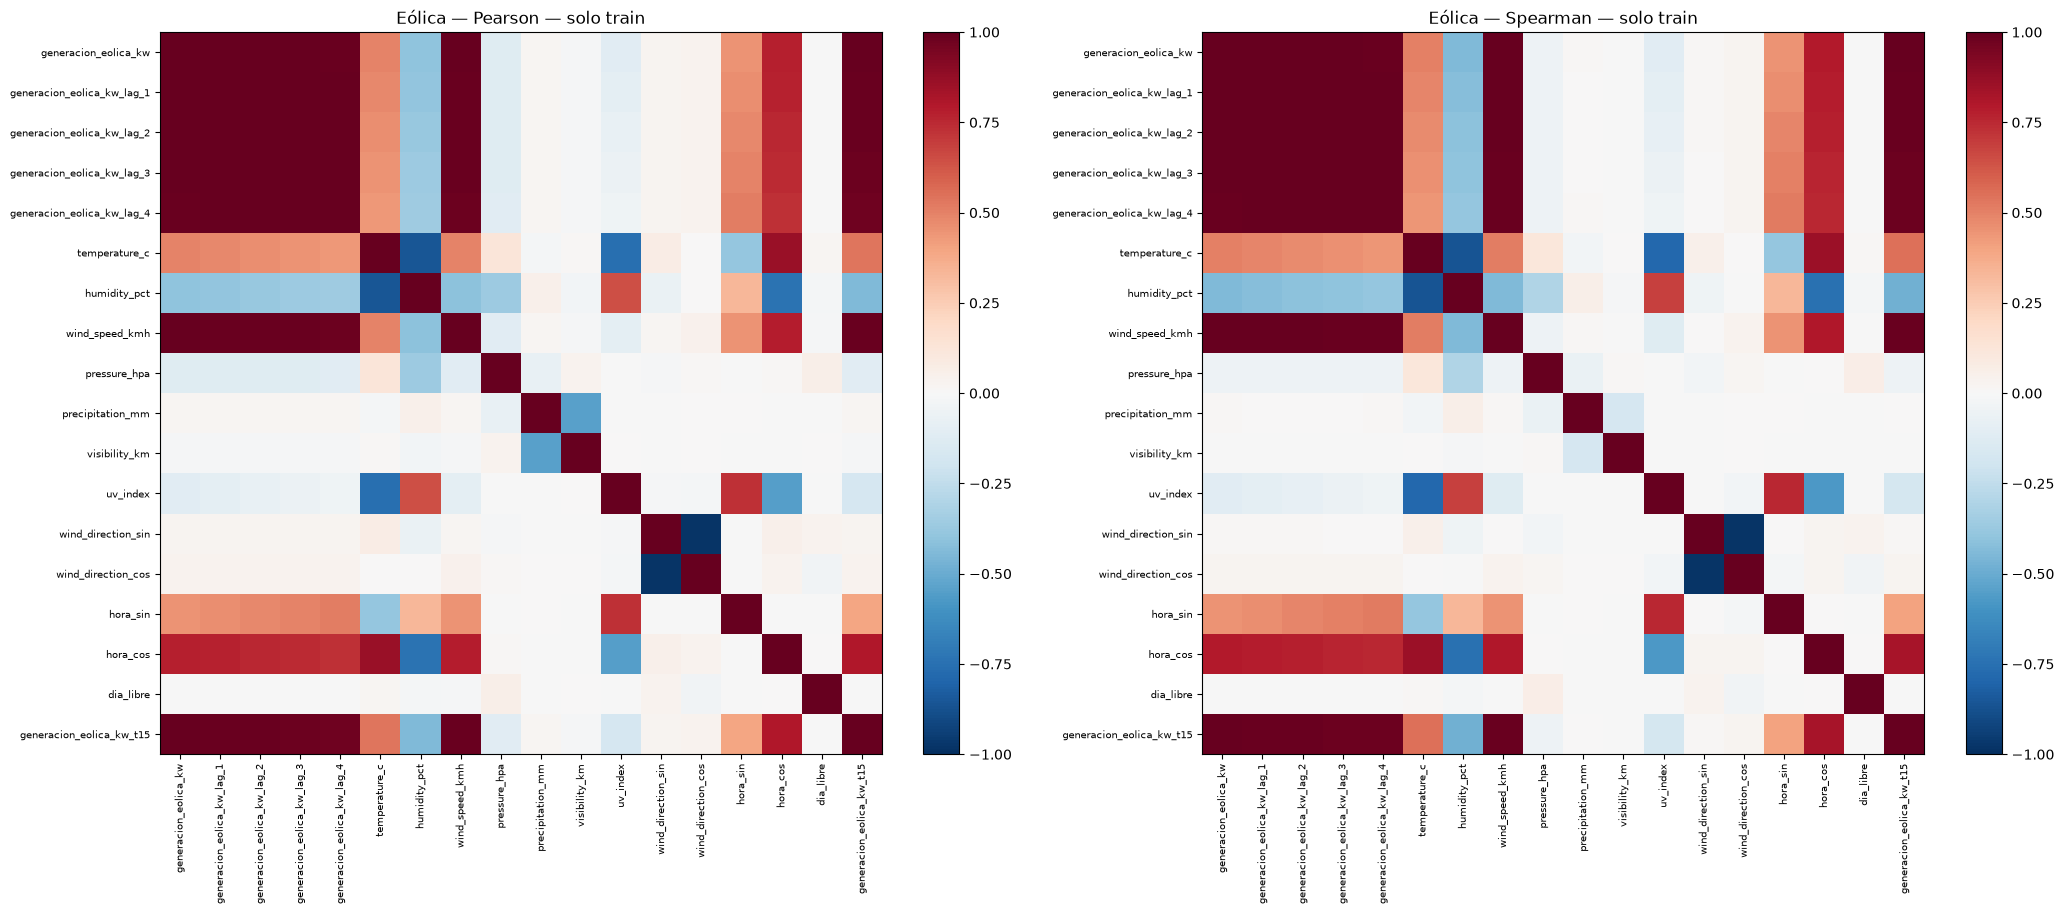

,pearson,spearman
generacion_eolica_kw,0.9926,0.9940
generacion_eolica_kw_lag_1,0.9890,0.9909
wind_speed_kmh,0.9861,0.9907
generacion_eolica_kw_lag_2,0.9847,0.9874
generacion_eolica_kw_lag_3,0.9799,0.9833
generacion_eolica_kw_lag_4,0.9745,0.9788
hora_cos,0.8036,0.8235
temperature_c,0.5371,0.5525
humidity_pct,-0.4431,-0.4796
hora_sin,0.3938,0.3985


Eólica: 63,384 ejemplos completos para este análisis.


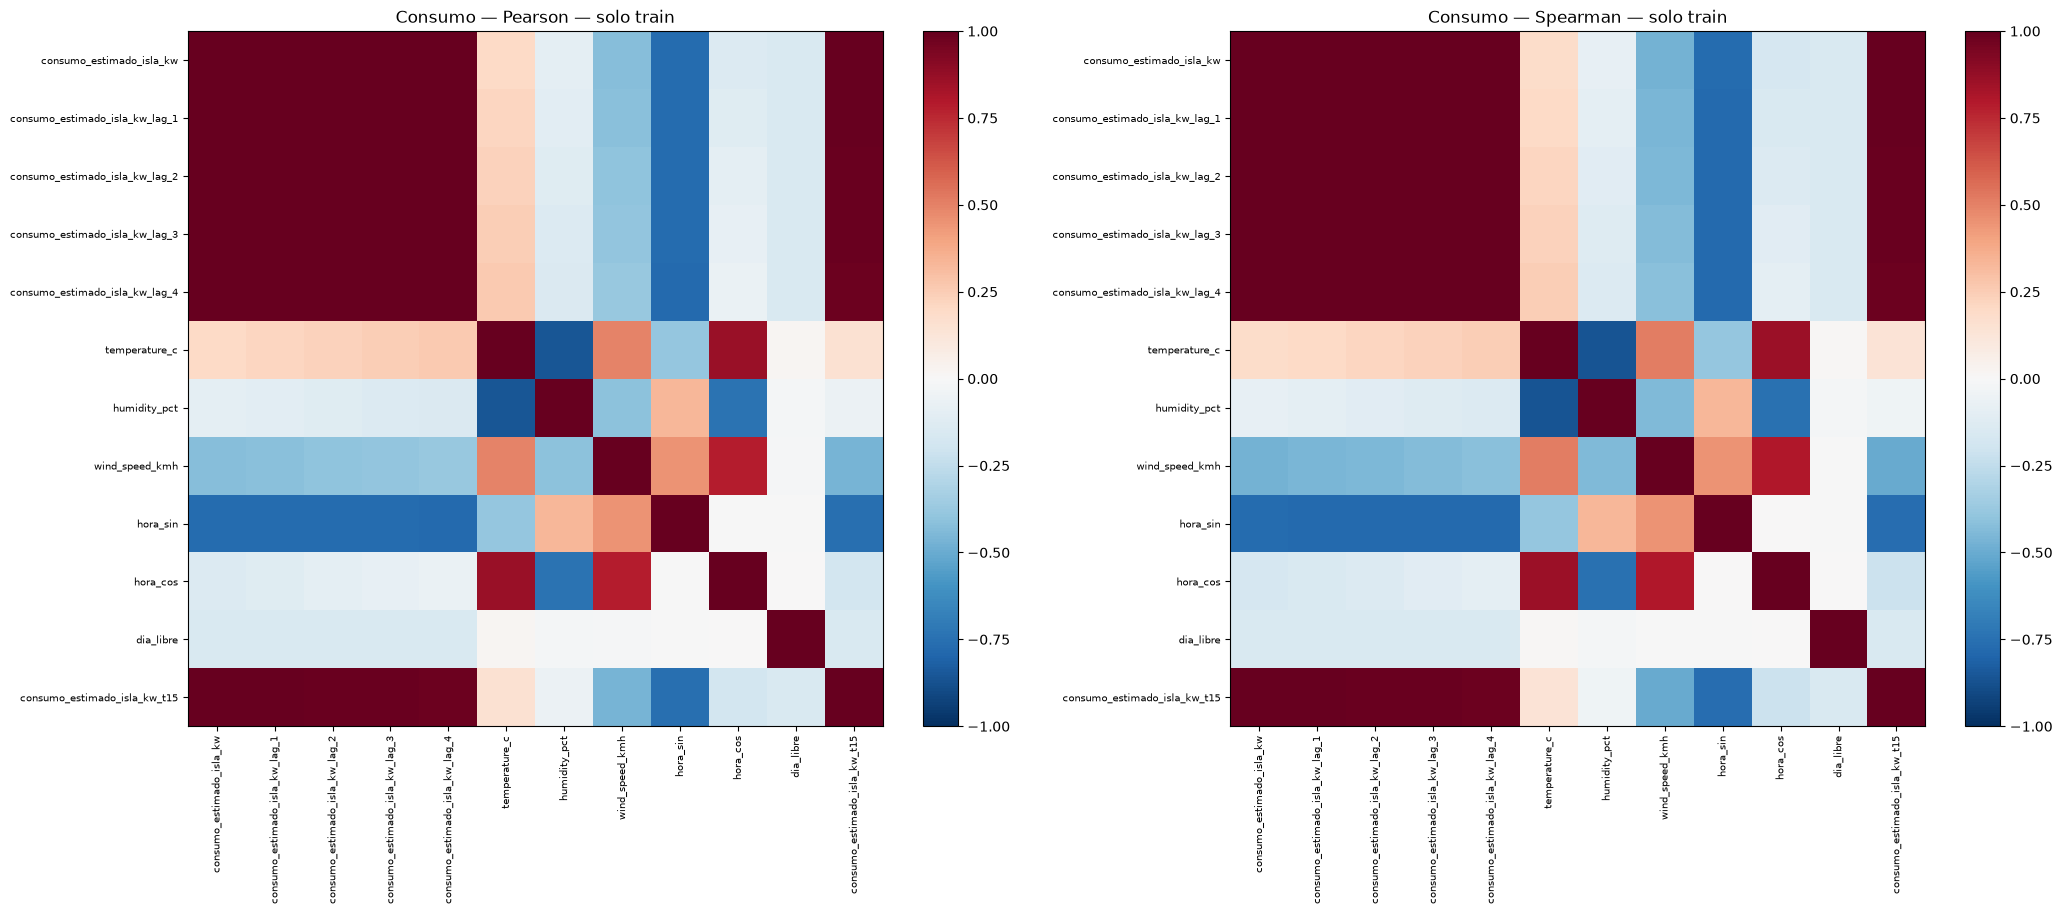

,pearson,spearman
consumo_estimado_isla_kw,0.9964,0.9963
consumo_estimado_isla_kw_lag_1,0.9939,0.9939
consumo_estimado_isla_kw_lag_2,0.9910,0.9909
consumo_estimado_isla_kw_lag_3,0.9874,0.9873
consumo_estimado_isla_kw_lag_4,0.9833,0.9832
hora_sin,-0.7554,-0.7627
wind_speed_kmh,-0.4633,-0.5062
hora_cos,-0.1841,-0.2169
dia_libre,-0.1544,-0.1561
temperature_c,0.1493,0.1347


Consumo: 63,372 ejemplos completos para este análisis.


In [52]:
correlaciones_objetivo = {}
for nombre, problema in problemas.items():
    features, target = problema['features'], problema['target']
    assert not set(features).intersection(TARGETS)
    tabla = train_futuro[features + [target]].dropna()
    fig, ejes = plt.subplots(1, 2, figsize=(21, 9))
    relaciones = {}
    for eje, metodo in zip(ejes, ['pearson', 'spearman']):
        matriz = tabla.corr(method=metodo)
        relaciones[metodo] = matriz[target].drop(target)
        imagen = eje.imshow(matriz, vmin=-1, vmax=1, cmap='RdBu_r')
        eje.set_xticks(range(len(matriz)), matriz.columns, rotation=90, fontsize=7)
        eje.set_yticks(range(len(matriz)), matriz.index, fontsize=7)
        eje.set_title(f'{nombre} — {metodo.capitalize()} — solo train')
        eje.grid(False)
        fig.colorbar(imagen, ax=eje, fraction=0.046)
    plt.tight_layout()
    plt.show()
    correlaciones_objetivo[nombre] = pd.DataFrame(relaciones)
    display(correlaciones_objetivo[nombre].sort_values(
        'pearson', key=abs, ascending=False).round(4))
    print(f'{nombre}: {len(tabla):,} ejemplos completos para este análisis.')

### 13.2 Comparar el presente con el futuro y medir el cambio

Las matrices anteriores resumen asociaciones. Ahora veremos directamente los pares de valores para las dos señales.

**Panel izquierdo de cada fila:**

- Eje horizontal: valor conocido en t.
- Eje vertical: valor de la serie en t+15.
- Diagonal: ambos valores serían iguales. Es la hipótesis de persistencia, no la predicción de un modelo entrenado.

**Panel derecho de cada fila:** histograma de `valor futuro − valor actual`. Un cambio positivo indica aumento y uno negativo, descenso. Una concentración alrededor de cero sugiere cambios pequeños frecuentes, aunque las colas pueden contener episodios importantes.

**No lo confundas con evaluar ML:** aún no hay predicciones ni residuos de un modelo. La tabla final resume estos cambios en kW, no la precisión de un algoritmo.

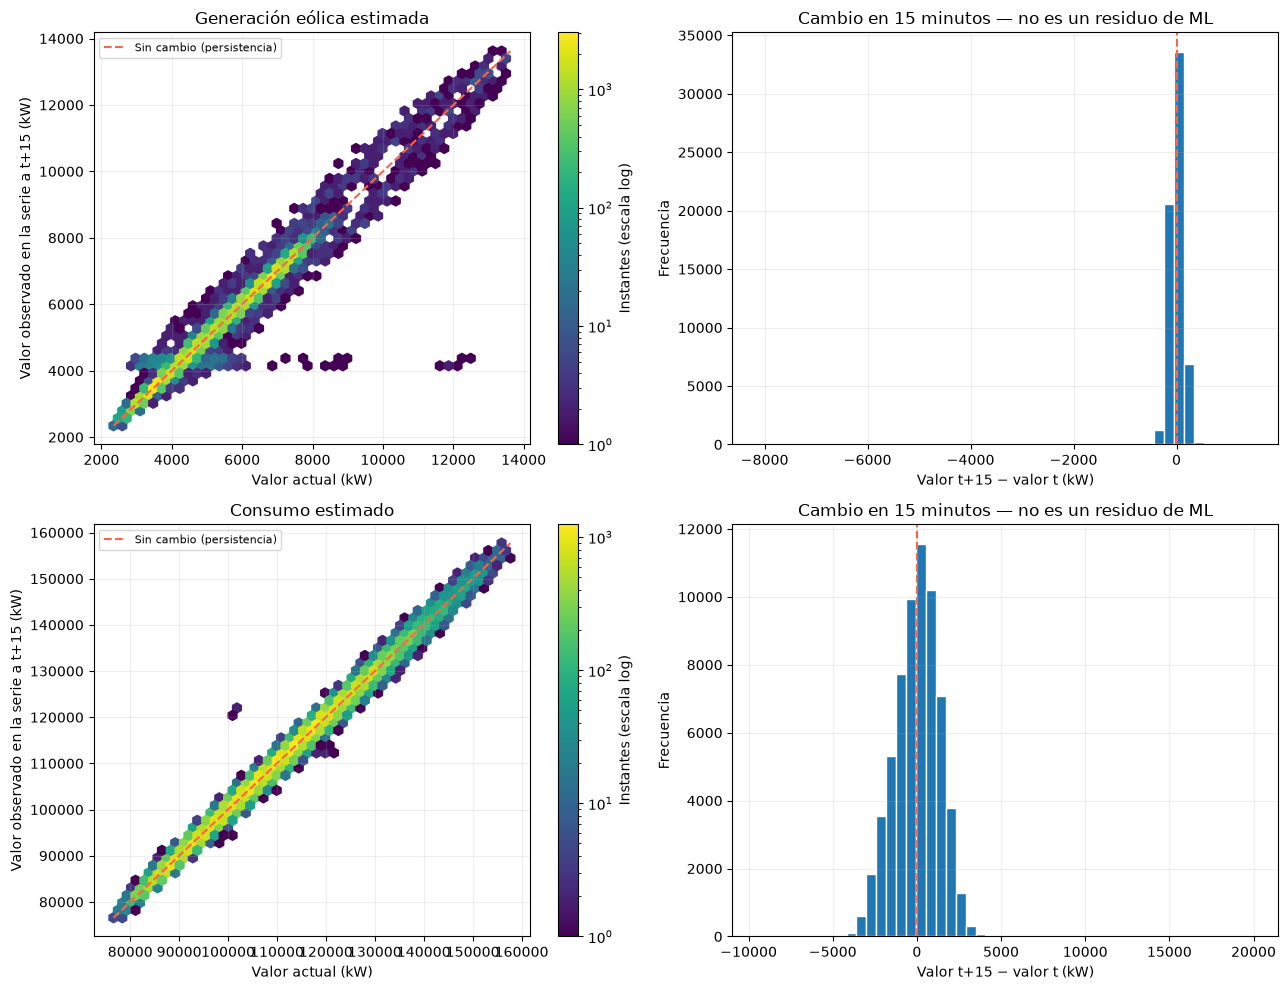

,generacion_eolica_kw,consumo_estimado_isla_kw
count,63384.000,63384.000
mean,0.152,-1.598
std,179.158,1306.932
min,-8141.792,-9483.260
1%,-305.480,-3066.439
50%,-0.561,84.220
99%,356.194,2706.241
max,1493.898,19994.680


In [53]:
fig, ejes = plt.subplots(2, 2, figsize=(13, 10))
cambios = {}
for fila, (actual, target) in enumerate(zip(OBJETIVOS_ACTUALES, TARGETS)):
    pares = train_futuro[[actual, target]].dropna()
    eje = ejes[fila, 0]
    imagen = eje.hexbin(pares[actual], pares[target], gridsize=45, mincnt=1, bins='log')
    limites = [pares.min().min(), pares.max().max()]
    eje.plot(limites, limites, '--', color='tomato', label='Sin cambio (persistencia)')
    eje.set_xlabel('Valor actual (kW)')
    eje.set_ylabel('Valor observado en la serie a t+15 (kW)')
    eje.set_title(NOMBRES[actual])
    eje.legend(fontsize=8)
    fig.colorbar(imagen, ax=eje, label='Instantes (escala log)')
    delta = pares[target] - pares[actual]
    cambios[actual] = delta.describe(percentiles=[0.01, 0.5, 0.99])
    ejes[fila, 1].hist(delta, bins=50, edgecolor='white')
    ejes[fila, 1].axvline(0, color='tomato', linestyle='--')
    ejes[fila, 1].set_title('Cambio en 15 minutos — no es un residuo de ML')
    ejes[fila, 1].set_xlabel('Valor t+15 − valor t (kW)')
    ejes[fila, 1].set_ylabel('Frecuencia')
plt.tight_layout()
plt.show()
display(pd.DataFrame(cambios).round(3))

## 14. Redundancia y disponibilidad (PDF, págs. 32–50)

- `id` identifica una lectura, no explica la potencia. `station_id` deja de ser una fila independiente en la tabla insular.
- `wind_alert` se obtiene del viento actual; puede ser redundante y no se incorpora al primer conjunto candidato.
- Los cuatro retardos pueden estar muy correlacionados entre sí y aun así aportar información sobre una tendencia. No se eliminan automáticamente.
- Las columnas de auditoría se reservan para examinar calidad, no se añaden indiscriminadamente como predictores.
- Se listan constantes y pares con |Pearson| ≥ 0,95 solo como **señales a investigar**, no como reglas de borrado.

Para árboles no hace falta escalar. Si se compara Ridge, se ajustará escalado solo dentro de cada entrenamiento mediante un `Pipeline`. VIF, RFE, Lasso e información mutua son alternativas, no pasos obligatorios que haya que aplicar todos.

**Experimentos posteriores:** señal actual sola; señal + retardos; señal + retardos + calendario/meteorología. Compararlos en las mismas ventanas temporales dirá si las variables adicionales realmente ayudan.

In [54]:
redundancias = []
for nombre, problema in problemas.items():
    tabla = train_futuro[problema['features']].dropna()
    constantes = tabla.columns[tabla.nunique() <= 1].tolist()
    print(f'{nombre} — entradas constantes en entrenamiento: {constantes or "ninguna"}')
    matriz = tabla.corr()
    for i, columna in enumerate(matriz.columns):
        for otra in matriz.columns[i + 1:]:
            r = matriz.loc[columna, otra]
            if pd.notna(r) and abs(r) >= 0.95:
                redundancias.append({'problema': nombre, 'variable_1': columna,
                                     'variable_2': otra, 'pearson': r})
redundancias = pd.DataFrame(redundancias, columns=[
    'problema', 'variable_1', 'variable_2', 'pearson'])
display(redundancias.round(4))

Eólica — entradas constantes en entrenamiento: ninguna
Consumo — entradas constantes en entrenamiento: ninguna


,problema,variable_1,variable_2,pearson
0,Eólica,generacion_eolica_kw,generacion_eolica_kw_lag_1,0.9981
1,Eólica,generacion_eolica_kw,generacion_eolica_kw_lag_2,0.9957
2,Eólica,generacion_eolica_kw,generacion_eolica_kw_lag_3,0.9926
3,Eólica,generacion_eolica_kw,generacion_eolica_kw_lag_4,0.9890
4,Eólica,generacion_eolica_kw,wind_speed_kmh,0.9926
5,Eólica,generacion_eolica_kw_lag_1,generacion_eolica_kw_lag_2,0.9981
6,Eólica,generacion_eolica_kw_lag_1,generacion_eolica_kw_lag_3,0.9957
7,Eólica,generacion_eolica_kw_lag_1,generacion_eolica_kw_lag_4,0.9926
8,Eólica,generacion_eolica_kw_lag_1,wind_speed_kmh,0.9909
9,Eólica,generacion_eolica_kw_lag_2,generacion_eolica_kw_lag_3,0.9981


### 14.1 Cuántos ejemplos completos tiene cada problema

**La tabla anterior** señala entradas muy correlacionadas. No ha seleccionado ni eliminado ninguna.

Ahora contamos las filas que tienen todas las entradas candidatas y su respuesta futura disponibles.

**Por qué puede haber menos ejemplos para consumo:** sus retardos se buscan en este CSV y pueden faltar al comienzo o después de un hueco. Ambos modelos necesitan además una respuesta futura conocida.

**Qué significa la tabla:** disponibilidad de datos, no rendimiento. No estamos usando la prueba para escoger el modelo.

In [55]:
elegibilidad = []
for nombre, problema in problemas.items():
    columnas = problema['features'] + [problema['target']]
    for bloque, tabla in conjuntos.items():
        elegibilidad.append({'problema': nombre, 'conjunto': bloque,
                             'filas': len(tabla),
                             'ejemplos_completos': len(tabla.dropna(subset=columnas))})
display(pd.DataFrame(elegibilidad))

,problema,conjunto,filas,ejemplos_completos
0,Eólica,train,63390,63384
1,Eólica,validacion,21128,21125
2,Eólica,prueba,21132,21129
3,Consumo,train,63390,63372
4,Consumo,validacion,21128,21121
5,Consumo,prueba,21132,21129


## 15. Conclusiones reproducibles y límites

La siguiente celda redacta observaciones a partir de los datos del bloque de entrenamiento, no de cifras inventadas ni del comportamiento del test. Deben leerse junto con las figuras, no como una selección final del mejor modelo.

**Límites metodológicos que quedan declarados:**

1. Ambos objetivos son estimaciones. Los patrones pueden provenir de sus fórmulas de construcción y no acreditan precisión frente a mediciones reales.
2. El generador de consumo normaliza por meses completos y calibra pico/media sobre toda la serie. El consumo actual del CSV, por tanto, es una señal retrospectiva, no una entrada operativa disponible en tiempo real. Un split correcto no elimina esta limitación. Para producción harían falta mediciones o un estimador causal con parámetros fijados usando solo el pasado.
3. La limpieza admite interpolación usando el vecino posterior; si `was_imputed` deja de ser cero hay que revisar su efecto también en las variables derivadas y sus retardos.
4. El periodo de prueba no cubre un año completo y no permite demostrar generalización a todas las estaciones del año.
5. No se han ajustado imputadores, escaladores, selectores ni modelos. Las medias meteorológicas por timestamp son agregaciones simultáneas, no ajustes sobre el futuro.

In [56]:
hora_consumo = perfil.groupby('hora')['consumo_estimado_isla_kw'].mean()
r_eolica = correlaciones_objetivo['Eólica'].loc['generacion_eolica_kw', 'pearson']
r_consumo = correlaciones_objetivo['Consumo'].loc['consumo_estimado_isla_kw', 'pearson']
resumen_cambios = []
for actual, target in zip(OBJETIVOS_ACTUALES, TARGETS):
    completos = train_futuro[[actual, target]].dropna()
    cambio_abs = (completos[target] - completos[actual]).abs()
    resumen_cambios.append(
        f'- **{NOMBRES[actual]}:** mediana del cambio absoluto a 15 min '
        f'{cambio_abs.median():,.1f} kW; percentil 95 {cambio_abs.quantile(0.95):,.1f} kW. '
        'Habrá que comparar con persistencia, no solo con la media histórica.'
    )

### 15.1 Convertir los cálculos en una lectura del EDA

La celda anterior preparó las horas de máximo/mínimo, las correlaciones y los cambios absolutos a quince minutos.

**Ahora** reunimos esos números en un resumen legible. No se introducen valores a mano: si cambia el entrenamiento y vuelves a ejecutar todo, se actualizará el texto.

**Cómo interpretarlo:** separa hechos descriptivos (fechas ausentes, rango horario, variación observada) de decisiones pendientes (qué modelo o conjunto de variables funciona mejor). Estas últimas requieren validación.

In [57]:
texto = (
    f'### Lectura de los resultados\n\n'
    f'- El CSV contiene **{len(datos):,} filas**, pero solo **{len(isla):,} instantes**. '
    'Las señales eléctricas repetidas se han contado una sola vez.\n'
    f'- El EDA utiliza **{len(isla_train):,} instantes de entrenamiento**. '
    'No se han explorado las distribuciones de validación o prueba.\n'
    f'- En el calendario de entrenamiento faltan **{len(calendario_train) - len(isla_train):,} '
    f'instantes**, repartidos en **{len(huecos)} huecos**; no se han interpolado.\n'
    f'- Hay **{len(anomalias)} filas de estación con anomalías marcadas** y '
    f'**{int(eda.was_imputed.sum())} imputadas** en entrenamiento. Los extremos se conservan.\n'
    f'- En la simulación de consumo, el mínimo horario medio aparece a las '
    f'**{hora_consumo.idxmin():02d}:00** y el máximo a las **{hora_consumo.idxmax():02d}:00** '
    '(hora de Aruba). Es coherencia de la serie modelada, no validación de demanda real.\n'
    f'- La correlación entre valor actual y futuro a 15 min es '
    f'**{r_eolica:.4f} en generación** y **{r_consumo:.4f} en consumo**. '
    'Son asociaciones, no métricas de un modelo entrenado: no equivalen a un porcentaje de aciertos.\n'
    '- Los retardos comparten mucha información. Compararemos bloques de entradas con y sin '
    'retardos, en lugar de eliminarlos automáticamente por correlación.\n'
    + '\n'.join(resumen_cambios)
)
display(Markdown(texto))

### Lectura de los resultados

- El CSV contiene **316,968 filas**, pero solo **105,656 instantes**. Las señales eléctricas repetidas se han contado una sola vez.
- El EDA utiliza **63,393 instantes de entrenamiento**. No se han explorado las distribuciones de validación o prueba.
- En el calendario de entrenamiento faltan **2,312 instantes**, repartidos en **2 huecos**; no se han interpolado.
- Hay **6 filas de estación con anomalías marcadas** y **0 imputadas** en entrenamiento. Los extremos se conservan.
- En la simulación de consumo, el mínimo horario medio aparece a las **04:00** y el máximo a las **19:00** (hora de Aruba). Es coherencia de la serie modelada, no validación de demanda real.
- La correlación entre valor actual y futuro a 15 min es **0.9926 en generación** y **0.9964 en consumo**. Son asociaciones, no métricas de un modelo entrenado: no equivalen a un porcentaje de aciertos.
- Los retardos comparten mucha información. Compararemos bloques de entradas con y sin retardos, en lugar de eliminarlos automáticamente por correlación.
- **Generación eólica estimada:** mediana del cambio absoluto a 15 min 83.0 kW; percentil 95 245.4 kW. Habrá que comparar con persistencia, no solo con la media histórica.
- **Consumo estimado:** mediana del cambio absoluto a 15 min 897.6 kW; percentil 95 2,523.0 kW. Habrá que comparar con persistencia, no solo con la media histórica.

## 16. Qué está terminado y qué viene después

### Completado aquí

- [x] Problema y procedencia de las dos señales documentados.
- [x] Estructura, tipos, duplicados, ausencias, continuidad, rangos y anomalías comprobados.
- [x] Una fila por instante; comparación meteorológica entre estaciones.
- [x] Estadísticas, histogramas, boxplots, series y perfiles locales con explicaciones.
- [x] Dependencia temporal y cambios a 15 minutos estudiados sin cruzar huecos.
- [x] Objetivos t+15 y retardos de consumo preparados **en memoria** y comprobados.
- [x] Correlaciones Pearson/Spearman, constantes y redundancia analizadas solo en train.
- [x] Cortes temporales y separación por fecha del objetivo comprobados.

### Siguiente fase: notebook de entrenamiento, no más limpieza automática

1. Fijar entradas disponibles en t y las hipótesis de simulación. No introducir columnas `*_t15` en X.
2. Comparar **persistencia** y media de entrenamiento con Ridge y Gradient Boosting; no asumir que gana el más complejo.
3. Comparar conjuntos candidatos de variables mediante ventanas temporales. Mantener unidos todos los datos del mismo instante; no aplicar KFold aleatorio.
4. Al usar `TimeSeriesSplit`, recordar que `gap` cuenta filas y que existen huecos. Es preferible construir cortes por fecha y purgar etiquetas que alcancen el siguiente bloque. Cualquier preprocesamiento aprendido se ajusta dentro de cada fold.
5. Elegir variables e hiperparámetros con validación; evaluar una vez en la prueba final con MAE, RMSE y R², por separado para generación y consumo.
6. Entonces sí: gráficas de observado frente a predicho, residuos y comparación de errores entre ventanas (PDF, págs. 124–126).
7. Guardar el pipeline completo, esquema de entradas, horizonte y versiones, y comprobar la recarga.

**Este notebook no exporta ni sobrescribe datasets ni modelos.** Las tablas `conjuntos` y `problemas` son una preparación exploratoria reproducible para la siguiente fase; sus ausencias no se rellenan sin una política explícita.